# ML Pipeline Visualization
## SHAP Explainability & Data Degradation in Tabular Data

Figures for all 13 pipeline steps. Every figure is saved as a 300 dpi PNG to `report_figures/`.

In [1]:
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import os, warnings
warnings.filterwarnings('ignore')

os.makedirs('report_figures', exist_ok=True)

plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 10,
    'axes.titlesize': 12,
    'axes.titleweight': 'bold',
    'axes.labelsize': 10,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'figure.dpi': 100,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.15,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'grid.linestyle': '--',
    'axes.axisbelow': True,
})

SIZE_COLORS  = {'small': '#4E79A7', 'medium': '#F28E2B', 'large': '#59A14F'}
TIER_COLORS  = {'high': '#E15759', 'medium': '#F28E2B', 'low': '#76B7B2'}
CORR_COLORS  = {
    'missing_mcar':   '#4E79A7',
    'missing_mar':    '#59A14F',
    'missing_mnar':   '#F28E2B',
    'gaussian_noise': '#E15759',
    'extreme_values': '#76B7B2',
    'value_swap':     '#B07AA1',
    'scaling':        '#9C755F',
}
METRIC_COLORS = ['#4E79A7', '#F28E2B', '#59A14F']
BAL_COLOR     = '#4E79A7'
IMBAL_COLOR   = '#E15759'
SHAP_COLOR    = '#4E79A7'

ds_df    = pd.read_csv('step1_selected_datasets.csv')
load_df  = pd.read_csv('step2_load_summary.csv')
pre_df   = pd.read_csv('step3_preprocessing_summary.csv')
base_df  = pd.read_csv('step5_baseline_evaluation.csv')
shap_s   = pd.read_csv('step6_shap_summary.csv')
plan_df  = pd.read_csv('step7_corruption_plan.csv')
res_df   = pd.read_csv('step9_performance_results.csv')

DATASETS       = ds_df['name'].tolist()
imbalanced_set = set(pre_df[pre_df['imbalanced']]['name'].tolist())
print(f"Loaded data for {len(DATASETS)} datasets")
print(f"Imbalanced datasets: {sorted(imbalanced_set)}")
print(f"Step 9 results: {len(res_df)} experiments")
print("Output: report_figures/")

Loaded data for 13 datasets
Imbalanced datasets: ['bank-marketing', 'connect-4', 'ozone-level-8hr', 'satimage', 'segment']
Step 9 results: 807 experiments
Output: report_figures/


## Step 1 — Dataset Selection

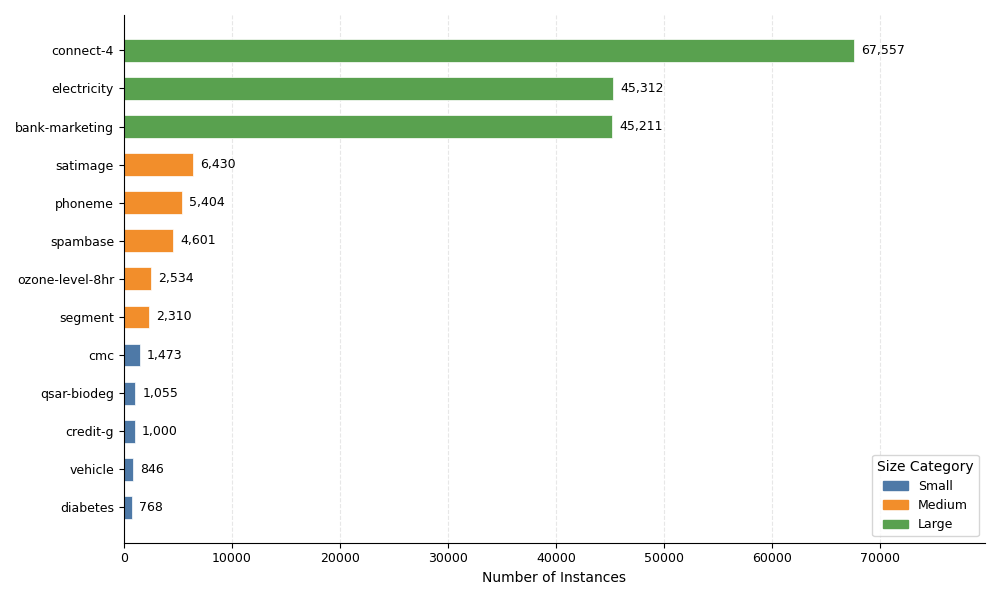

Saved: fig1_1_dataset_sizes.png


In [2]:
# Fig 1.1 — Dataset sizes coloured by size category
fig, ax = plt.subplots(figsize=(10, 6))
sdf = ds_df.sort_values('n_instances')
colors = [SIZE_COLORS[s] for s in sdf['size']]
bars = ax.barh(sdf['name'], sdf['n_instances'], color=colors,
               height=0.6, edgecolor='white', linewidth=0.5)
for bar, v in zip(bars, sdf['n_instances']):
    ax.text(bar.get_width() + sdf['n_instances'].max()*0.01,
            bar.get_y() + bar.get_height()/2,
            f'{int(v):,}', va='center', fontsize=9)
patches = [mpatches.Patch(color=c, label=s.capitalize())
           for s, c in SIZE_COLORS.items()]
ax.legend(handles=patches, title='Size Category', loc='lower right', fontsize=9)
ax.set_xlabel('Number of Instances')
# ax.set_title('Figure 1.1 — Dataset Sizes (coloured by size category)')
ax.set_xlim(0, sdf['n_instances'].max() * 1.18)
ax.grid(axis='x', alpha=0.3); ax.grid(axis='y', alpha=0)
plt.tight_layout()
fig.savefig('report_figures/fig1_1_dataset_sizes.png', dpi=300)
plt.show(); print("Saved: fig1_1_dataset_sizes.png")

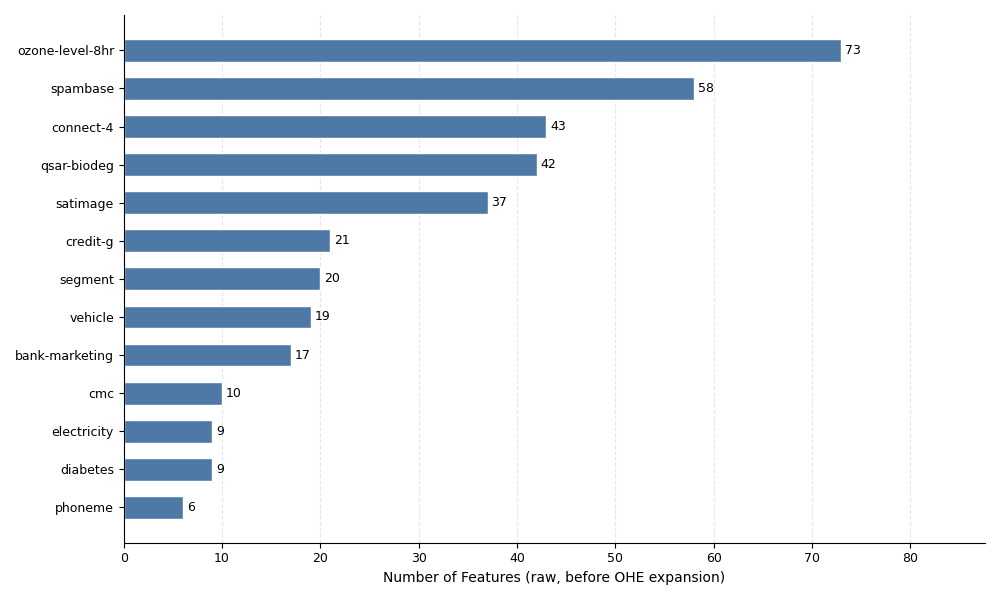

Saved: fig1_2_features_per_dataset.png


In [3]:
# Fig 1.2 — Features per dataset (raw, before OHE)
fig, ax = plt.subplots(figsize=(10, 6))
sdf = ds_df.sort_values('n_features')
bars = ax.barh(sdf['name'], sdf['n_features'], color='#4E79A7',
               height=0.6, edgecolor='white')
for bar, v in zip(bars, sdf['n_features']):
    ax.text(bar.get_width() + 0.4, bar.get_y() + bar.get_height()/2,
            str(int(v)), va='center', fontsize=9)
ax.set_xlabel('Number of Features (raw, before OHE expansion)')
# ax.set_title('Figure 1.2 — Raw Feature Count per Dataset')
ax.set_xlim(0, sdf['n_features'].max() * 1.2)
ax.grid(axis='x', alpha=0.3); ax.grid(axis='y', alpha=0)
plt.tight_layout()
fig.savefig('report_figures/fig1_2_features_per_dataset.png', dpi=300)
plt.show(); print("Saved: fig1_2_features_per_dataset.png")

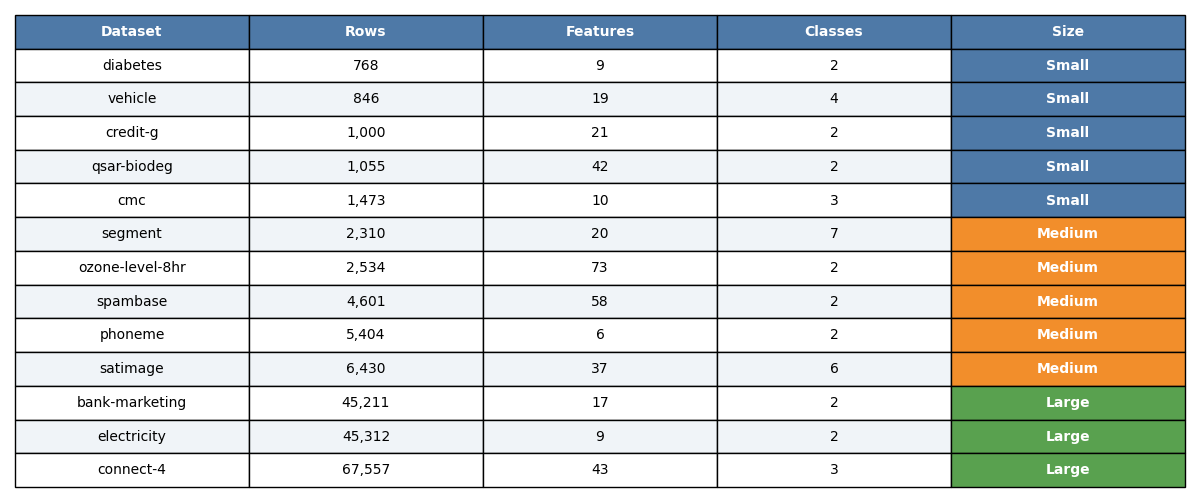

Saved: fig1_3_dataset_table.png


In [4]:
# Fig 1.3 — Summary table
fig, ax = plt.subplots(figsize=(12, 5))
ax.axis('off')
tdata = ds_df[['name','n_instances','n_features','n_classes','size']].copy()
tdata.columns = ['Dataset','Rows','Features','Classes','Size']
tdata['Rows']     = tdata['Rows'].apply(lambda x: f'{int(x):,}')
tdata['Features'] = tdata['Features'].astype(int)
tdata['Classes']  = tdata['Classes'].astype(int)
tdata['Size']     = tdata['Size'].str.capitalize()
col_labels = tdata.columns.tolist()
cell_text  = tdata.values.tolist()
tbl = ax.table(cellText=cell_text, colLabels=col_labels,
               loc='center', cellLoc='center')
tbl.auto_set_font_size(False); tbl.set_fontsize(10); tbl.scale(1, 1.7)
for j in range(len(col_labels)):
    tbl[(0,j)].set_facecolor('#4E79A7')
    tbl[(0,j)].set_text_props(color='white', fontweight='bold')
for i in range(1, len(cell_text)+1):
    for j in range(len(col_labels)):
        if i % 2 == 0:
            tbl[(i,j)].set_facecolor('#F0F4F8')
    sz = cell_text[i-1][4].lower()
    tbl[(i,4)].set_facecolor(SIZE_COLORS[sz])
    tbl[(i,4)].set_text_props(color='white', fontweight='bold')
# ax.set_title('Figure 1.3 — Dataset Summary Table',
#              fontsize=12, fontweight='bold', y=0.98)
plt.tight_layout()
fig.savefig('report_figures/fig1_3_dataset_table.png', dpi=300)
plt.show(); print("Saved: fig1_3_dataset_table.png")

## Step 2 — Data Loading (Imbalanced Datasets)

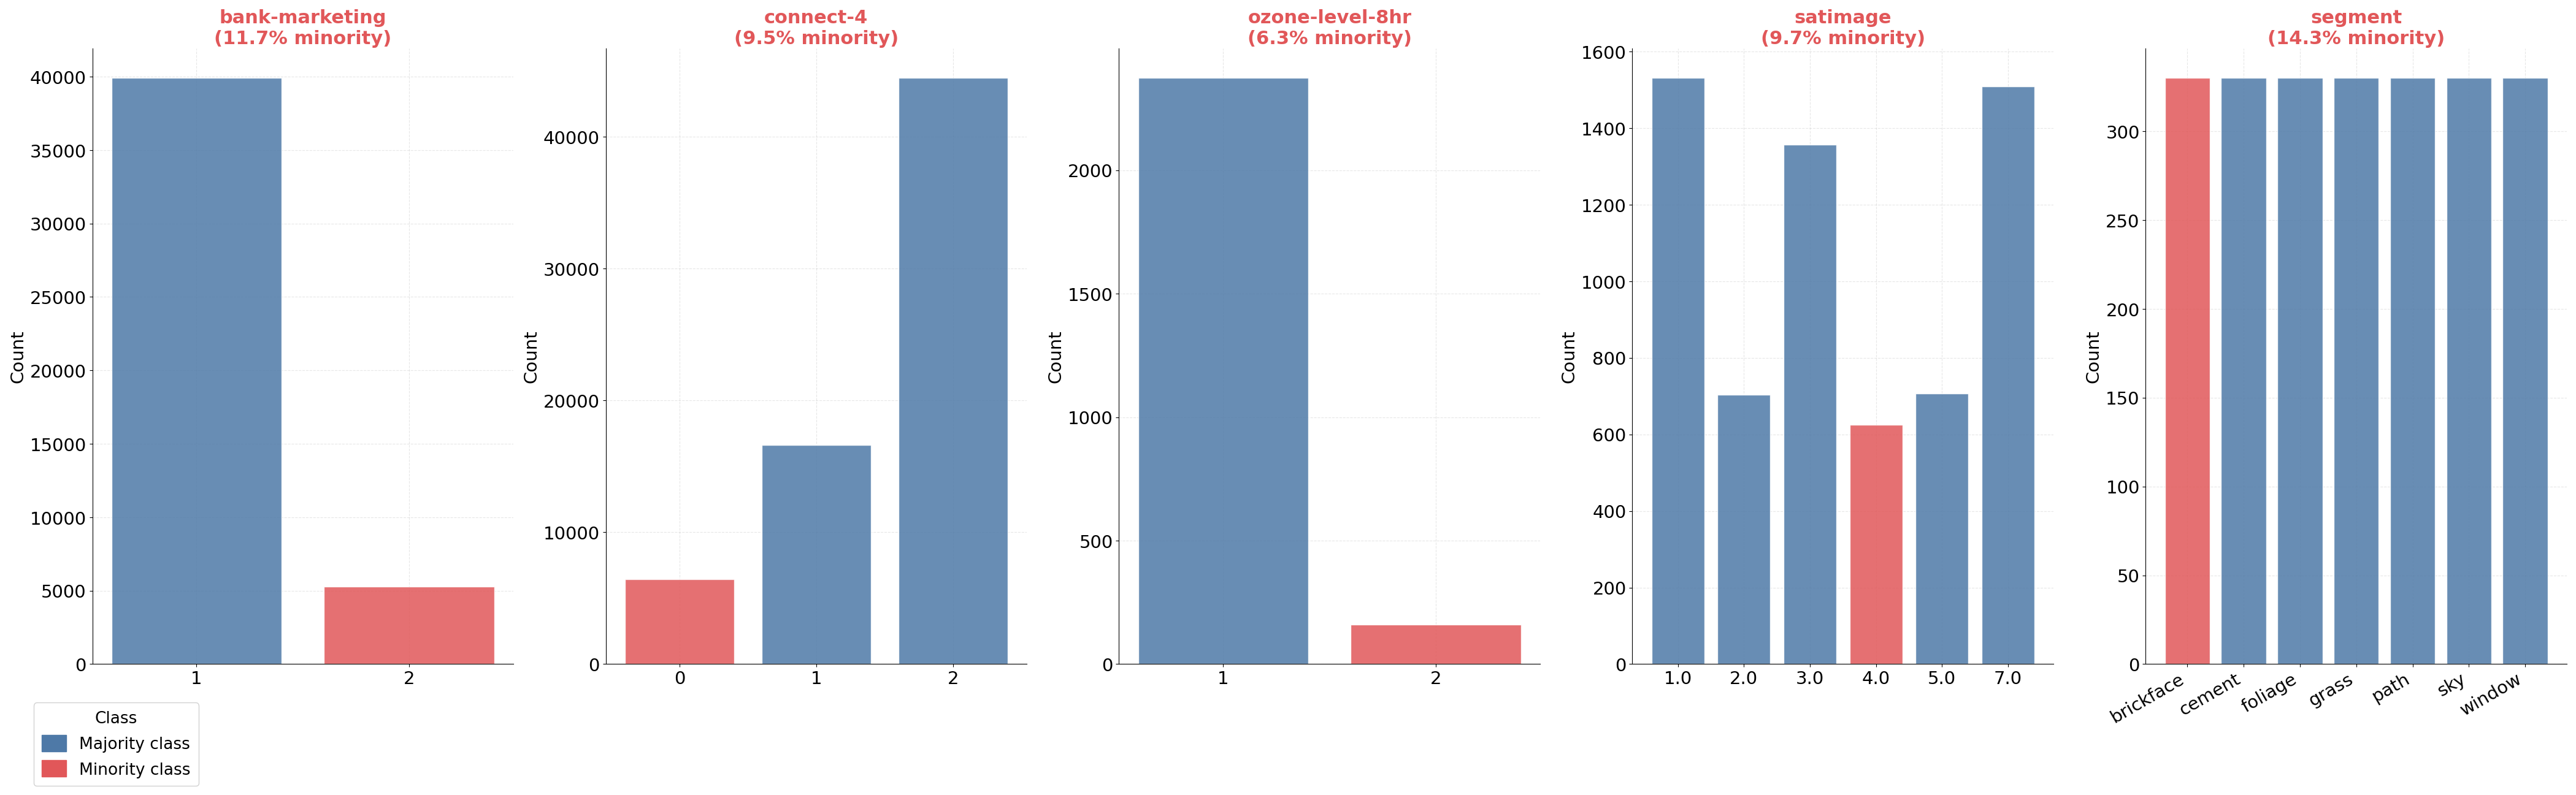

Saved: fig2_1_class_distribution_imbalanced.png


In [5]:
# Fig 2.1 — Class distribution for the 5 imbalanced datasets only
# Raw CSVs have 'target' as the class column name
imbal_list   = sorted(imbalanced_set)   # consistent ordering
minority_pct = dict(zip(pre_df['name'], pre_df['minority_pct']))

p1 = mpatches.Patch(color=BAL_COLOR,   label='Majority class')
p2 = mpatches.Patch(color=IMBAL_COLOR, label='Minority class')

fig, axes = plt.subplots(1, 5, figsize=(42, 12))
for ax, name in zip(axes, imbal_list):
    raw    = pd.read_csv(f'data/raw/{name}.csv')
    counts = raw['target'].value_counts().sort_index()
    colors = [IMBAL_COLOR if c == counts.idxmin() else BAL_COLOR
              for c in counts.index]
    ax.bar(range(len(counts)), counts.values, color=colors,
           alpha=0.85, edgecolor='white')
    ax.set_xticks(range(len(counts)))
    # Only rotate labels for segment (text class names), numerical labels stay upright
    rot = 30 if name == 'segment' else 0
    ha  = 'right' if name == 'segment' else 'center'
    ax.set_xticklabels([str(c) for c in counts.index],
                       fontsize=21, rotation=rot, ha=ha)
    ax.set_title(f'{name}\n({minority_pct[name]:.1f}% minority)',
                 fontsize=22, fontweight='bold', color=IMBAL_COLOR)
    ax.set_ylabel('Count', fontsize=21)
    ax.tick_params(labelsize=21)
    ax.grid(axis='y', alpha=0.3)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# Legend placed inside the last subplot (segment) away from bars and title
fig.legend(handles=[p1, p2], fontsize=19, title='Class',
           title_fontsize=19, loc='lower left', bbox_to_anchor=(0.01, -0.08),
           framealpha=0.9, borderpad=0.5, handlelength=1.5, handleheight=1.2)
# fig.suptitle('Figure 2.1 — Class Distribution: Imbalanced Datasets Only',
#              fontsize=13, fontweight='bold', y=1.04)
plt.tight_layout()
fig.savefig('report_figures/fig2_1_class_distribution_imbalanced.png',
            dpi=300, bbox_inches='tight')
plt.show(); print("Saved: fig2_1_class_distribution_imbalanced.png")

## Step 3 — Preprocessing

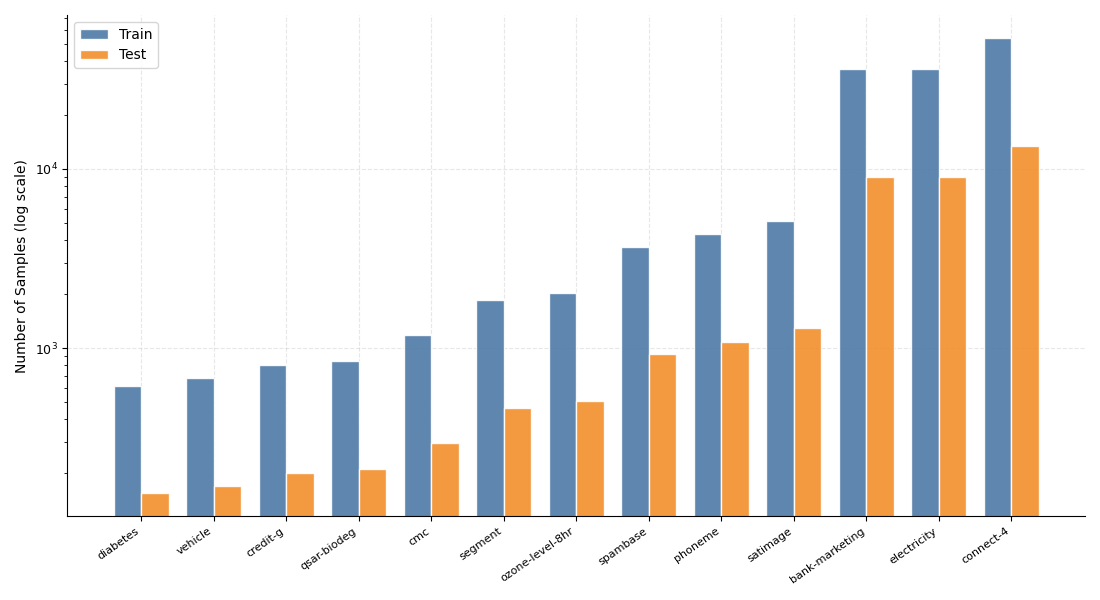

Saved: fig3_1_train_test_split.png


In [6]:
# Fig 3.1 — Train / test split per dataset (log scale)
fig, ax = plt.subplots(figsize=(11, 6))
x = np.arange(len(pre_df))
w = 0.38
ax.bar(x - w/2, pre_df['n_train'], w, label='Train',
       color='#4E79A7', alpha=0.9, edgecolor='white')
ax.bar(x + w/2, pre_df['n_test'],  w, label='Test',
       color='#F28E2B', alpha=0.9, edgecolor='white')
ax.set_xticks(x)
ax.set_xticklabels(pre_df['name'], rotation=35, ha='right', fontsize=8)
ax.set_yscale('log')
ax.set_ylabel('Number of Samples (log scale)')
# ax.set_title('Figure 3.1 — Train / Test Split per Dataset')
ax.legend(fontsize=10)
plt.tight_layout()
fig.savefig('report_figures/fig3_1_train_test_split.png', dpi=300)
plt.show(); print("Saved: fig3_1_train_test_split.png")

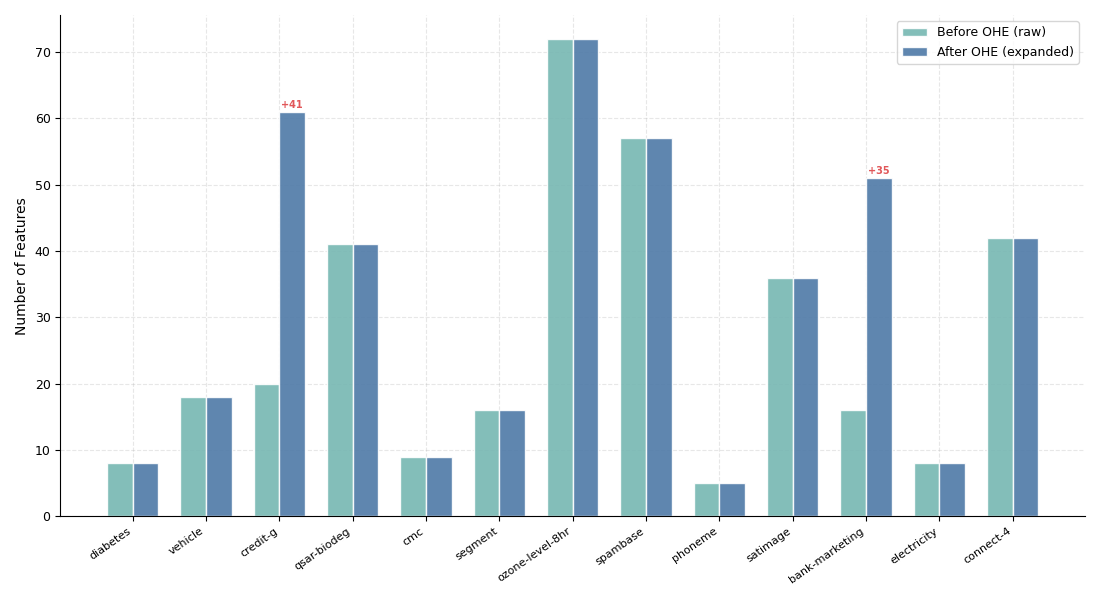

Saved: fig3_2_ohe_expansion.png


In [7]:
# Fig 3.2 — Feature count before vs after OHE expansion
fig, ax = plt.subplots(figsize=(11, 6))
x = np.arange(len(pre_df))
w = 0.35
pre_df['n_original'] = pre_df['n_num_cols'] + pre_df['n_cat_cols']
ax.bar(x - w/2, pre_df['n_original'],    w, label='Before OHE (raw)',
       color='#76B7B2', alpha=0.9, edgecolor='white')
ax.bar(x + w/2, pre_df['n_features_out'], w, label='After OHE (expanded)',
       color='#4E79A7', alpha=0.9, edgecolor='white')
for i, (bef, aft) in enumerate(zip(pre_df['n_original'], pre_df['n_features_out'])):
    if aft > bef:
        ax.annotate(f'+{aft-bef}',
                    xy=(i + w/2, aft), xytext=(0, 3),
                    textcoords='offset points',
                    ha='center', fontsize=7, color='#E15759', fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(pre_df['name'], rotation=35, ha='right', fontsize=8)
ax.set_ylabel('Number of Features')
# ax.set_title('Figure 3.2 — Feature Count Before vs After One-Hot Encoding\n'
#              '(+N = OHE expansion, datasets with only numerical features unchanged)')
ax.legend(fontsize=9)
plt.tight_layout()
fig.savefig('report_figures/fig3_2_ohe_expansion.png', dpi=300)
plt.show(); print("Saved: fig3_2_ohe_expansion.png")

## Step 5 — Baseline Performance

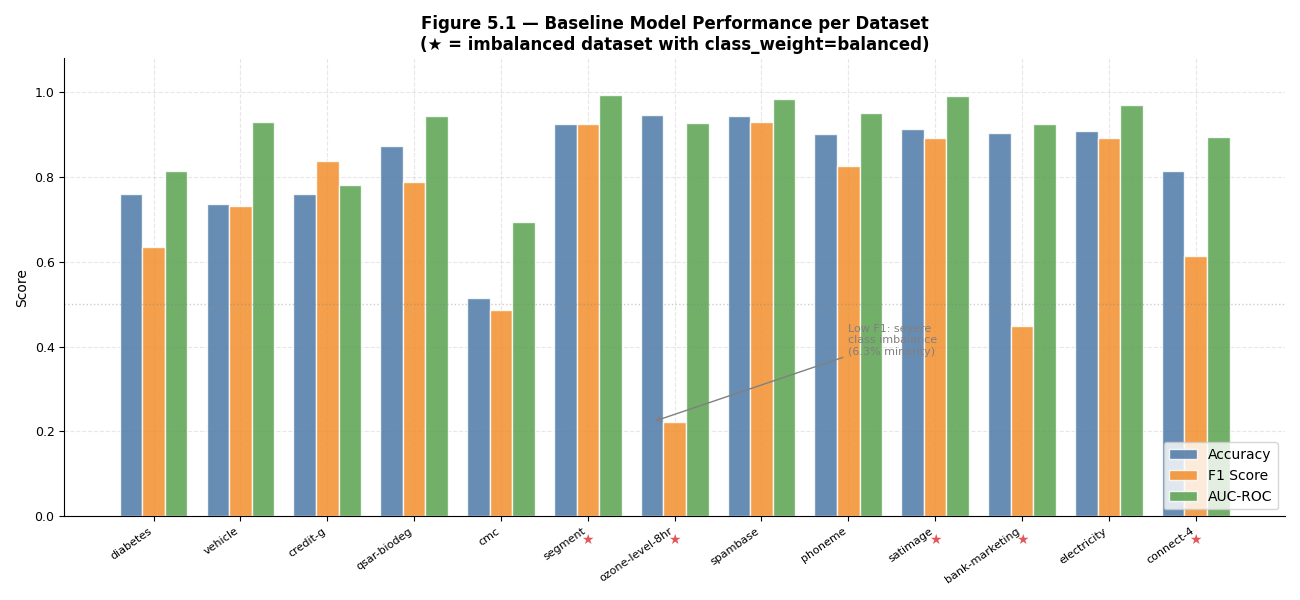

Saved: fig5_1_baseline_performance.png


In [8]:
# Fig 5.1 — Accuracy, F1, AUC side by side with imbalanced datasets highlighted
fig, ax = plt.subplots(figsize=(13, 6))
metrics = ['accuracy', 'f1', 'auc']
labels  = ['Accuracy', 'F1 Score', 'AUC-ROC']
x = np.arange(len(base_df))
w = 0.26
for i, (m, lbl, color) in enumerate(zip(metrics, labels, METRIC_COLORS)):
    ax.bar(x + (i-1)*w, base_df[m], w, label=lbl,
           color=color, alpha=0.85, edgecolor='white')
for i, name in enumerate(base_df['name']):
    if name in imbalanced_set:
        ax.text(x[i], -0.06, '★', ha='center', fontsize=10,
                color=IMBAL_COLOR, transform=ax.get_xaxis_transform())
ax.set_xticks(x)
ax.set_xticklabels(base_df['name'], rotation=35, ha='right', fontsize=8)
ax.set_ylabel('Score')
ax.set_ylim(0, 1.08)
ax.set_title('Figure 5.1 — Baseline Model Performance per Dataset\n'
             '(★ = imbalanced dataset with class_weight=balanced)')
ax.legend(fontsize=10, loc='lower right')
ax.axhline(0.5, color='gray', linestyle=':', alpha=0.4, linewidth=1)
ozone_idx = list(base_df['name']).index('ozone-level-8hr')
ozone_f1  = float(base_df.loc[base_df['name']=='ozone-level-8hr','f1'].values[0])
ax.annotate('Low F1: severe\nclass imbalance\n(6.3% minority)',
            xy=(ozone_idx - 0.26, ozone_f1),
            xytext=(ozone_idx + 2, 0.38),
            arrowprops=dict(arrowstyle='->', color='gray', lw=1),
            fontsize=8, color='gray', ha='left')
plt.tight_layout()
fig.savefig('report_figures/fig5_1_baseline_performance.png', dpi=300)
plt.show(); print("Saved: fig5_1_baseline_performance.png")

## Step 6 — SHAP Feature Importance

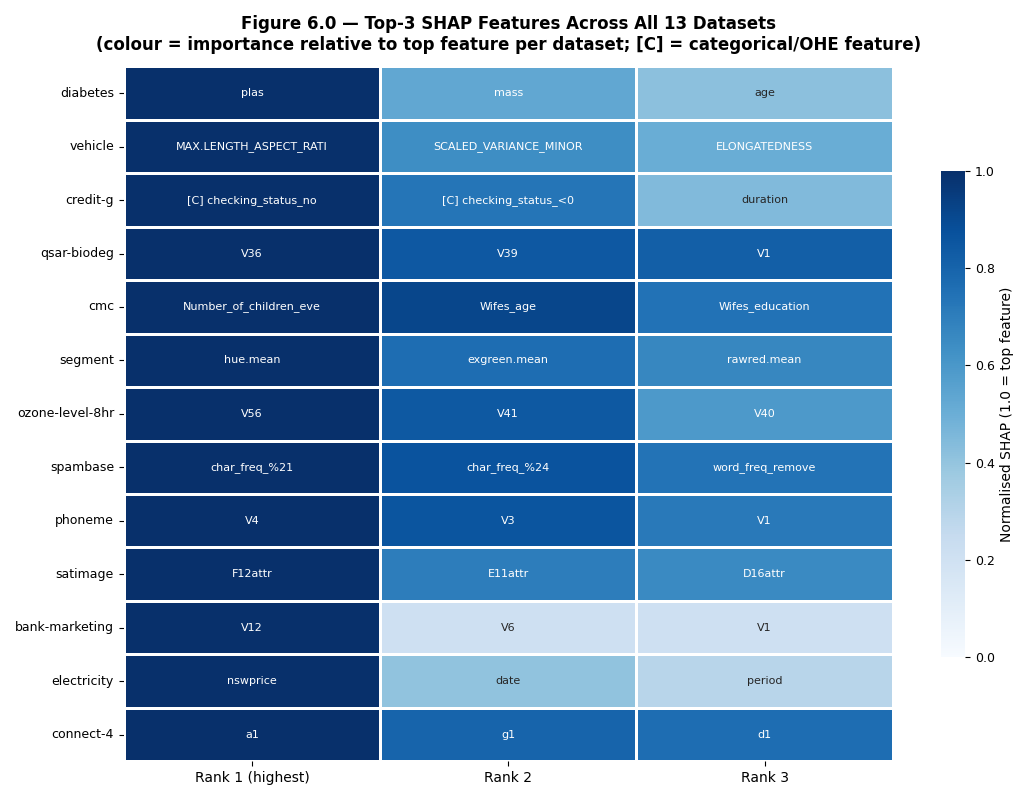

Saved: fig6_0_shap_combined_top3.png


In [9]:
# Fig 6.0 — Combined: top-3 SHAP features across all 13 datasets (annotated heatmap)
heat_vals   = np.zeros((len(DATASETS), 3))
heat_labels = [['' for _ in range(3)] for _ in DATASETS]

for i, name in enumerate(DATASETS):
    shap_df = pd.read_csv(f'shap/{name}_shap_importance.csv')
    top3    = shap_df.head(3)
    mx      = top3['shap_importance'].max()
    for j, (_, row) in enumerate(top3.iterrows()):
        heat_vals[i, j] = row['shap_importance'] / mx
        feat = (row['feature']
                .replace('num__', '')
                .replace('cat__', '[C] '))
        heat_labels[i][j] = feat[:22] if len(feat) > 22 else feat

fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(heat_vals, ax=ax, cmap='Blues', vmin=0, vmax=1,
            annot=heat_labels, fmt='s', annot_kws={'size': 8},
            linewidths=0.8, linecolor='white',
            cbar_kws={'label': 'Normalised SHAP (1.0 = top feature)', 'shrink': 0.7})
ax.set_xticklabels(['Rank 1 (highest)', 'Rank 2', 'Rank 3'], fontsize=10)
ax.set_yticklabels(DATASETS, rotation=0, fontsize=9)
ax.set_title('Figure 6.0 — Top-3 SHAP Features Across All 13 Datasets\n'
             '(colour = importance relative to top feature per dataset; '
             '[C] = categorical/OHE feature)',
             pad=12)
plt.tight_layout()
fig.savefig('report_figures/fig6_0_shap_combined_top3.png', dpi=300)
plt.show(); print("Saved: fig6_0_shap_combined_top3.png")

In [10]:
# Fig 6.1–6.13 — Top-10 SHAP importance per dataset (one PNG each)
print("Generating 13 individual SHAP importance plots...")
for name in DATASETS:
    shap_df = pd.read_csv(f'shap/{name}_shap_importance.csv').head(10)
    shap_df['label'] = (shap_df['feature']
                        .str.replace('num__', '', regex=False)
                        .str.replace('cat__', '[C] ', regex=False))
    fig, ax = plt.subplots(figsize=(9, 5))
    bars = ax.barh(shap_df['label'][::-1],
                   shap_df['shap_importance'][::-1],
                   color=SHAP_COLOR, height=0.65,
                   edgecolor='white', alpha=0.9)
    xmax = shap_df['shap_importance'].max()
    for bar, v in zip(bars, shap_df['shap_importance'][::-1]):
        ax.text(bar.get_width() + xmax*0.01,
                bar.get_y() + bar.get_height()/2,
                f'{v:.4f}', va='center', fontsize=8)
    ax.set_xlabel('Mean |SHAP value|')
    ax.set_title(f'Figure 6 — SHAP Feature Importance: {name}\n'
                 f'(Top 10 by mean |SHAP|; [C] = categorical/OHE feature)')
    ax.set_xlim(0, xmax * 1.22)
    ax.grid(axis='x', alpha=0.3); ax.grid(axis='y', alpha=0)
    plt.tight_layout()
    safe = name.replace('-', '_')
    fig.savefig(f'report_figures/fig6_shap_{safe}.png', dpi=300)
    plt.close(fig)
    print(f"  Saved: fig6_shap_{safe}.png")
print("Done — 13 SHAP plots saved.")

Generating 13 individual SHAP importance plots...


  Saved: fig6_shap_diabetes.png


  Saved: fig6_shap_vehicle.png


  Saved: fig6_shap_credit_g.png


  Saved: fig6_shap_qsar_biodeg.png


...

  Saved: fig6_shap_spambase.png
  Saved: fig6_shap_phoneme.png


  Saved: fig6_shap_satimage.png


  Saved: fig6_shap_bank_marketing.png


  Saved: fig6_shap_electricity.png


  Saved: fig6_shap_connect_4.png
Done — 13 SHAP plots saved.


## Step 7 — Corruption Design

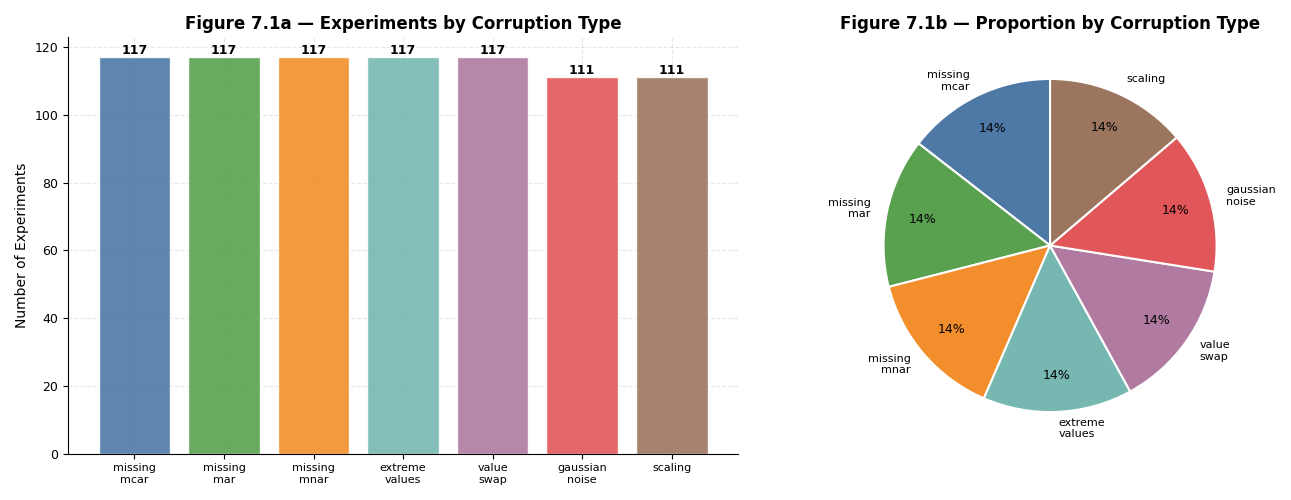

Saved: fig7_1_experiments_by_corruption.png


In [11]:
# Fig 7.1 — Experiment count by corruption type (bar + pie)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
corr_counts = plan_df['corruption_type'].value_counts()
cols = [CORR_COLORS.get(c,'#999') for c in corr_counts.index]

bars = ax1.bar(range(len(corr_counts)), corr_counts.values,
               color=cols, edgecolor='white', alpha=0.9)
ax1.set_xticks(range(len(corr_counts)))
ax1.set_xticklabels([c.replace('_','\n') for c in corr_counts.index], fontsize=8)
for bar, v in zip(bars, corr_counts.values):
    ax1.text(bar.get_x()+bar.get_width()/2, bar.get_height()+1,
             str(v), ha='center', fontsize=9, fontweight='bold')
ax1.set_ylabel('Number of Experiments')
ax1.set_title('Figure 7.1a — Experiments by Corruption Type')

wedges, texts, autos = ax2.pie(
    corr_counts.values,
    labels=[c.replace('_','\n') for c in corr_counts.index],
    colors=cols, autopct='%1.0f%%', startangle=90,
    pctdistance=0.78,
    wedgeprops=dict(edgecolor='white', linewidth=1.5))
for t in autos: t.set_fontsize(9)
for t in texts: t.set_fontsize(8)
ax2.set_title('Figure 7.1b — Proportion by Corruption Type')

plt.tight_layout()
fig.savefig('report_figures/fig7_1_experiments_by_corruption.png', dpi=300)
plt.show(); print("Saved: fig7_1_experiments_by_corruption.png")

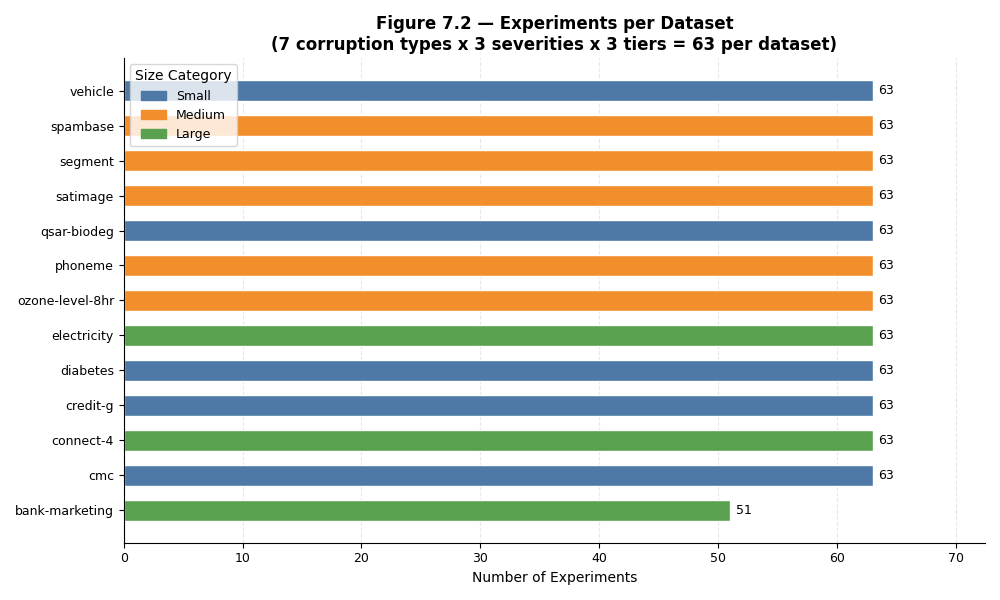

Saved: fig7_2_experiments_by_dataset.png


In [12]:
# Fig 7.2 — Experiment count by dataset
fig, ax = plt.subplots(figsize=(10, 6))
size_map  = dict(zip(ds_df['name'], ds_df['size']))
ds_counts = plan_df.groupby('dataset').size().sort_values()
colors    = [SIZE_COLORS[size_map[d]] for d in ds_counts.index]
bars = ax.barh(ds_counts.index, ds_counts.values,
               color=colors, height=0.6, edgecolor='white')
for bar, v in zip(bars, ds_counts.values):
    ax.text(bar.get_width()+0.5, bar.get_y()+bar.get_height()/2,
            str(v), va='center', fontsize=9)
patches = [mpatches.Patch(color=c, label=s.capitalize())
           for s, c in SIZE_COLORS.items()]
ax.legend(handles=patches, title='Size Category', fontsize=9)
ax.set_xlabel('Number of Experiments')
ax.set_title('Figure 7.2 — Experiments per Dataset\n'
             '(7 corruption types x 3 severities x 3 tiers = 63 per dataset)')
ax.set_xlim(0, ds_counts.max()*1.15)
ax.grid(axis='x', alpha=0.3); ax.grid(axis='y', alpha=0)
plt.tight_layout()
fig.savefig('report_figures/fig7_2_experiments_by_dataset.png', dpi=300)
plt.show(); print("Saved: fig7_2_experiments_by_dataset.png")

## Step 8 — Corruption Verification

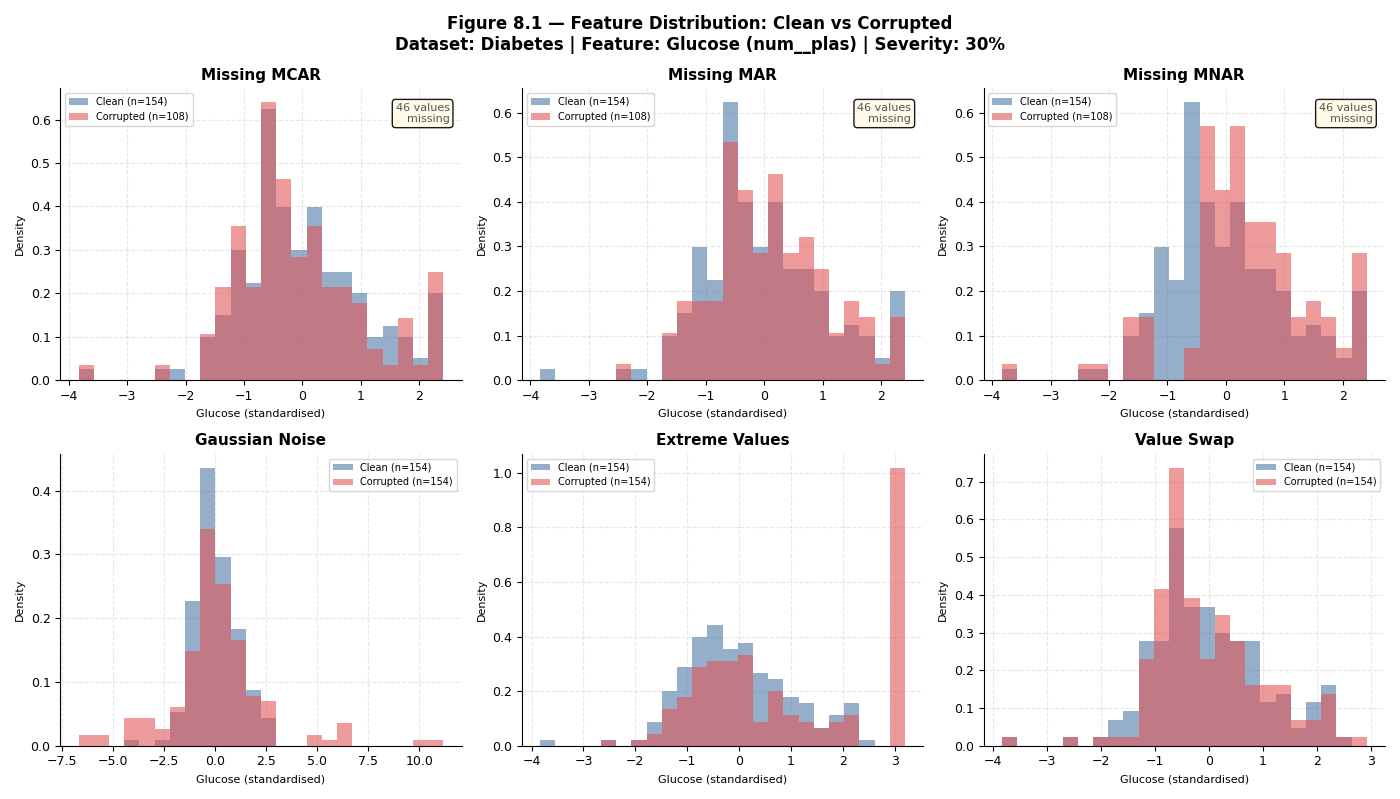

Saved: fig8_1_corruption_diabetes.png


In [13]:
# Fig 8.1 — Diabetes: clean vs corrupted, numerical feature (Glucose = num__plas)
clean_df   = pd.read_csv('data/processed/diabetes_test.csv')
clean_vals = clean_df['num__plas'].dropna().values
feature    = 'num__plas'

corruption_types = [
    ('missing_mcar',   'Missing MCAR'),
    ('missing_mar',    'Missing MAR'),
    ('missing_mnar',   'Missing MNAR'),
    ('gaussian_noise', 'Gaussian Noise'),
    ('extreme_values', 'Extreme Values'),
    ('value_swap',     'Value Swap'),
]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()
fig.suptitle('Figure 8.1 — Feature Distribution: Clean vs Corrupted\n'
             'Dataset: Diabetes | Feature: Glucose (num__plas) | Severity: 30%',
             fontsize=12, fontweight='bold')

for ax, (ct, label) in zip(axes, corruption_types):
    cdf      = pd.read_csv(f'data/corrupted/diabetes_high_{ct}_30.csv')
    cvals    = cdf[feature]
    n_miss   = int(cvals.isna().sum())
    cvals_nn = cvals.dropna().values
    lo = min(clean_vals.min(),
             cvals_nn.min() if len(cvals_nn) else clean_vals.min())
    hi = max(clean_vals.max(),
             cvals_nn.max() if len(cvals_nn) else clean_vals.max())
    bins = np.linspace(lo, hi, 25)
    ax.hist(clean_vals, bins=bins, alpha=0.6, color=BAL_COLOR,
            label=f'Clean (n={len(clean_vals)})', density=True)
    if len(cvals_nn):
        ax.hist(cvals_nn, bins=bins, alpha=0.6, color=IMBAL_COLOR,
                label=f'Corrupted (n={len(cvals_nn)})', density=True)
    ax.set_title(label, fontsize=11, fontweight='bold')
    ax.set_xlabel('Glucose (standardised)', fontsize=8)
    ax.set_ylabel('Density', fontsize=8)
    ax.legend(fontsize=7)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    if n_miss:
        ax.text(0.97, 0.95, f'{n_miss} values\nmissing',
                transform=ax.transAxes, ha='right', va='top', fontsize=8,
                color='#555',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='#FFFBE6', alpha=0.9))

plt.tight_layout()
fig.savefig('report_figures/fig8_1_corruption_diabetes.png', dpi=300)
plt.show(); print("Saved: fig8_1_corruption_diabetes.png")

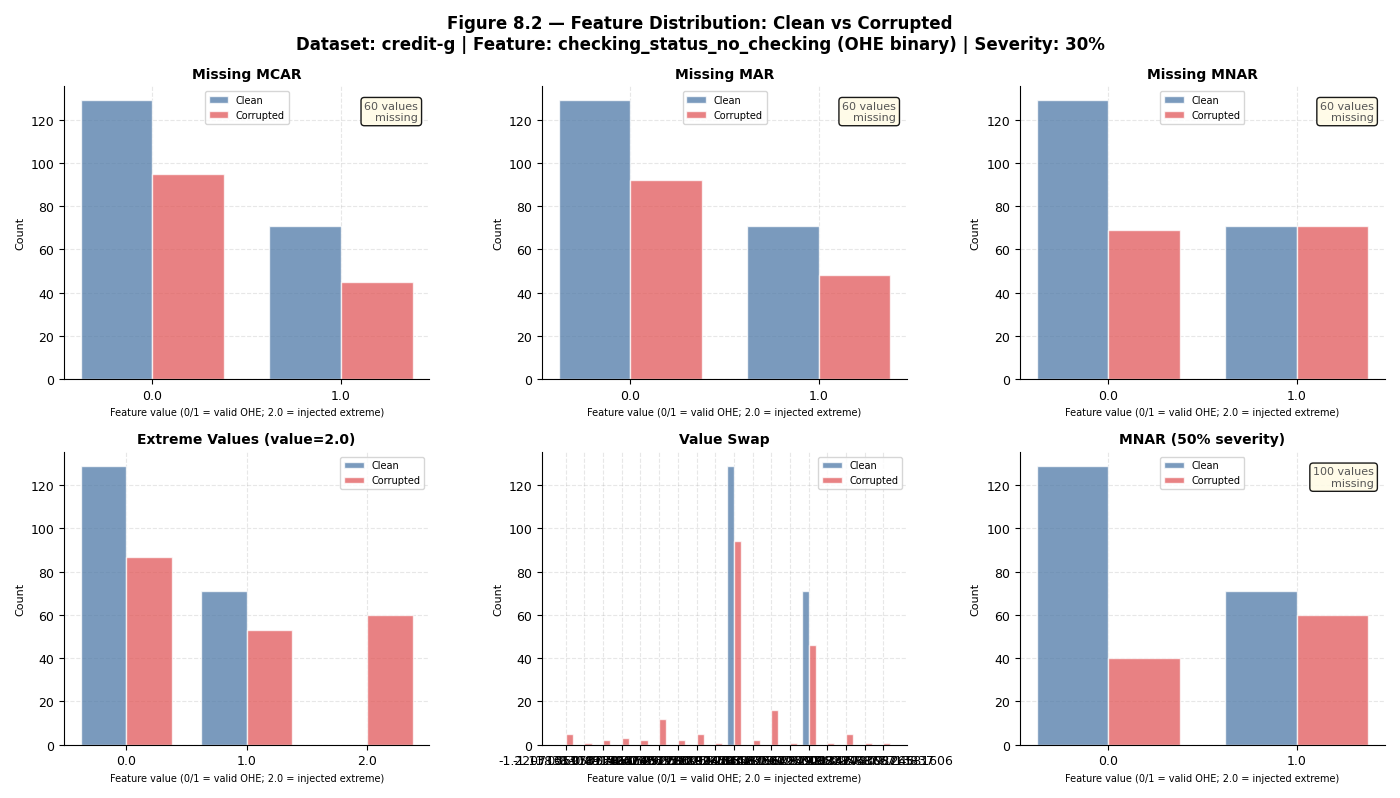

Saved: fig8_2_corruption_creditg.png


In [14]:
# Fig 8.2 — credit-g: clean vs corrupted, categorical OHE feature
# Top SHAP feature in credit-g is cat__checking_status_no checking (binary 0/1)
clean_df = pd.read_csv('data/processed/credit-g_test.csv')
feature  = 'cat__checking_status_no checking'

corruption_types = [
    ('missing_mcar',   'Missing MCAR'),
    ('missing_mar',    'Missing MAR'),
    ('missing_mnar',   'Missing MNAR'),
    ('extreme_values', 'Extreme Values (value=2.0)'),
    ('value_swap',     'Value Swap'),
    ('missing_mnar',   'MNAR (50% severity)'),   # reuse MNAR at 50% for contrast
]
severities = [30, 30, 30, 30, 30, 50]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()
fig.suptitle('Figure 8.2 — Feature Distribution: Clean vs Corrupted\n'
             'Dataset: credit-g | Feature: checking_status_no_checking (OHE binary) | Severity: 30%',
             fontsize=12, fontweight='bold')

clean_counts = clean_df[feature].value_counts().sort_index()

for ax, (ct, label), sev in zip(axes, corruption_types, severities):
    cdf    = pd.read_csv(f'data/corrupted/credit-g_high_{ct}_{sev}.csv')
    cvals  = cdf[feature]
    n_miss = int(cvals.isna().sum())

    all_vals = pd.concat([clean_df[feature], cvals.dropna()]).unique()
    all_vals = sorted(set([v for v in all_vals if not pd.isna(v)]))

    clean_vc  = clean_df[feature].value_counts().reindex(all_vals, fill_value=0)
    corr_vc   = cvals.dropna().value_counts().reindex(all_vals, fill_value=0)

    x_pos = np.arange(len(all_vals))
    w     = 0.38
    ax.bar(x_pos - w/2, clean_vc.values, w, color=BAL_COLOR,
           alpha=0.75, label='Clean', edgecolor='white')
    ax.bar(x_pos + w/2, corr_vc.values,  w, color=IMBAL_COLOR,
           alpha=0.75, label='Corrupted', edgecolor='white')
    ax.set_xticks(x_pos)
    ax.set_xticklabels([str(v) for v in all_vals], fontsize=9)
    ax.set_title(label, fontsize=10, fontweight='bold')
    ax.set_xlabel('Feature value (0/1 = valid OHE; 2.0 = injected extreme)', fontsize=7)
    ax.set_ylabel('Count', fontsize=8)
    ax.legend(fontsize=7)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    if n_miss:
        ax.text(0.97, 0.95, f'{n_miss} values\nmissing',
                transform=ax.transAxes, ha='right', va='top', fontsize=8,
                color='#555',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='#FFFBE6', alpha=0.9))

plt.tight_layout()
fig.savefig('report_figures/fig8_2_corruption_creditg.png', dpi=300)
plt.show(); print("Saved: fig8_2_corruption_creditg.png")

## Step 9 — Performance Results After Corruption

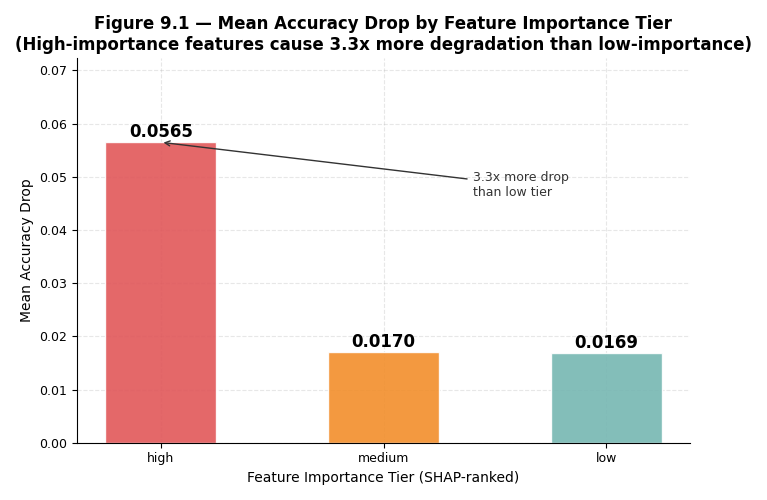

Saved: fig9_1_accuracy_drop_by_tier.png


In [15]:
# Fig 9.1 — Mean accuracy drop by feature importance tier (KEY FINDING)
fig, ax = plt.subplots(figsize=(7, 5))
tier_order = ['high', 'medium', 'low']
tier_means = res_df.groupby('tier')['accuracy_drop'].mean()[tier_order]
colors = [TIER_COLORS[t] for t in tier_order]
bars = ax.bar(tier_order, tier_means.values, color=colors,
              width=0.5, edgecolor='white', alpha=0.9)
for bar, v in zip(bars, tier_means.values):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.001,
            f'{v:.4f}', ha='center', fontsize=12, fontweight='bold')
ratio = tier_means['high'] / tier_means['low']
ax.set_xlabel('Feature Importance Tier (SHAP-ranked)')
ax.set_ylabel('Mean Accuracy Drop')
ax.set_title(f'Figure 9.1 — Mean Accuracy Drop by Feature Importance Tier\n'
             f'(High-importance features cause {ratio:.1f}x more degradation than low-importance)')
ax.set_ylim(0, tier_means.max()*1.28)
ax.annotate(f'{ratio:.1f}x more drop\nthan low tier',
            xy=(0, tier_means['high']),
            xytext=(1.4, tier_means['high']*0.82),
            arrowprops=dict(arrowstyle='->', color='#333'),
            fontsize=9, color='#333')
plt.tight_layout()
fig.savefig('report_figures/fig9_1_accuracy_drop_by_tier.png', dpi=300)
plt.show(); print("Saved: fig9_1_accuracy_drop_by_tier.png")

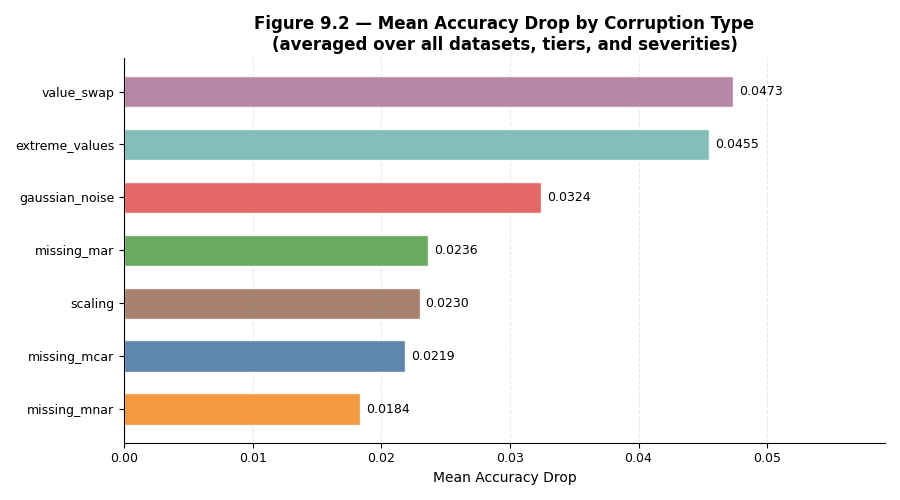

Saved: fig9_2_accuracy_drop_by_corruption.png


In [16]:
# Fig 9.2 — Mean accuracy drop by corruption type
fig, ax = plt.subplots(figsize=(9, 5))
corr_means = (res_df.groupby('corruption_type')['accuracy_drop']
              .mean().sort_values(ascending=True))
cols = [CORR_COLORS.get(c,'#999') for c in corr_means.index]
bars = ax.barh(corr_means.index, corr_means.values,
               color=cols, height=0.6, edgecolor='white', alpha=0.9)
xmax = corr_means.max()
for bar, v in zip(bars, corr_means.values):
    ax.text(bar.get_width()+xmax*0.01,
            bar.get_y()+bar.get_height()/2,
            f'{v:.4f}', va='center', fontsize=9)
ax.set_xlabel('Mean Accuracy Drop')
ax.set_title('Figure 9.2 — Mean Accuracy Drop by Corruption Type\n'
             '(averaged over all datasets, tiers, and severities)')
ax.set_xlim(0, xmax*1.25)
ax.grid(axis='x', alpha=0.3); ax.grid(axis='y', alpha=0)
plt.tight_layout()
fig.savefig('report_figures/fig9_2_accuracy_drop_by_corruption.png', dpi=300)
plt.show(); print("Saved: fig9_2_accuracy_drop_by_corruption.png")

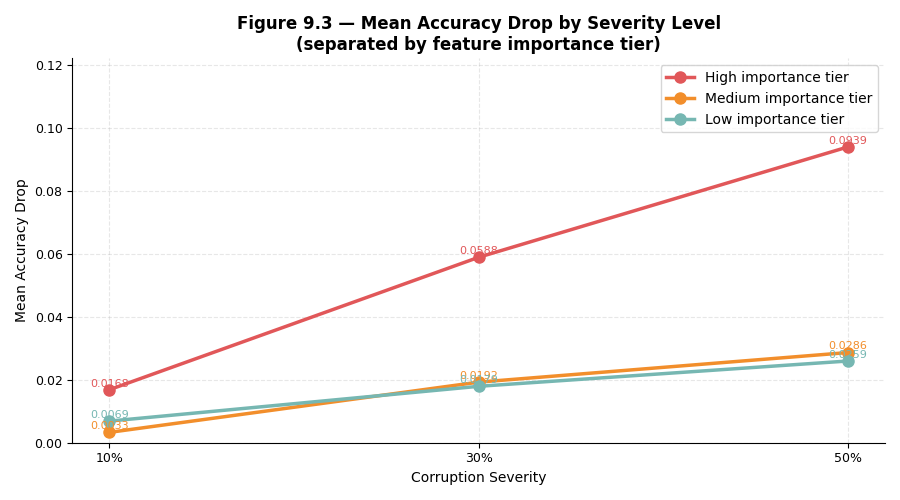

Saved: fig9_3_accuracy_drop_by_severity.png


In [17]:
# Fig 9.3 — Mean accuracy drop by severity, separated by tier (line chart)
fig, ax = plt.subplots(figsize=(9, 5))
tier_order = ['high', 'medium', 'low']
sev_vals   = sorted(res_df['severity'].unique())
sev_labels = [f'{int(s*100)}%' for s in sev_vals]
for tier in tier_order:
    sub   = res_df[res_df['tier']==tier]
    means = sub.groupby('severity')['accuracy_drop'].mean()[sev_vals].values
    ax.plot(sev_labels, means, marker='o', markersize=8, linewidth=2.5,
            color=TIER_COLORS[tier], label=f'{tier.capitalize()} importance tier')
    for x, y in zip(sev_labels, means):
        ax.text(x, y+0.001, f'{y:.4f}', ha='center', fontsize=8,
                color=TIER_COLORS[tier])
ax.set_xlabel('Corruption Severity')
ax.set_ylabel('Mean Accuracy Drop')
ax.set_title('Figure 9.3 — Mean Accuracy Drop by Severity Level\n'
             '(separated by feature importance tier)')
ax.legend(fontsize=10)
ymax = res_df.groupby(['tier','severity'])['accuracy_drop'].mean().max()
ax.set_ylim(0, ymax*1.3)
plt.tight_layout()
fig.savefig('report_figures/fig9_3_accuracy_drop_by_severity.png', dpi=300)
plt.show(); print("Saved: fig9_3_accuracy_drop_by_severity.png")

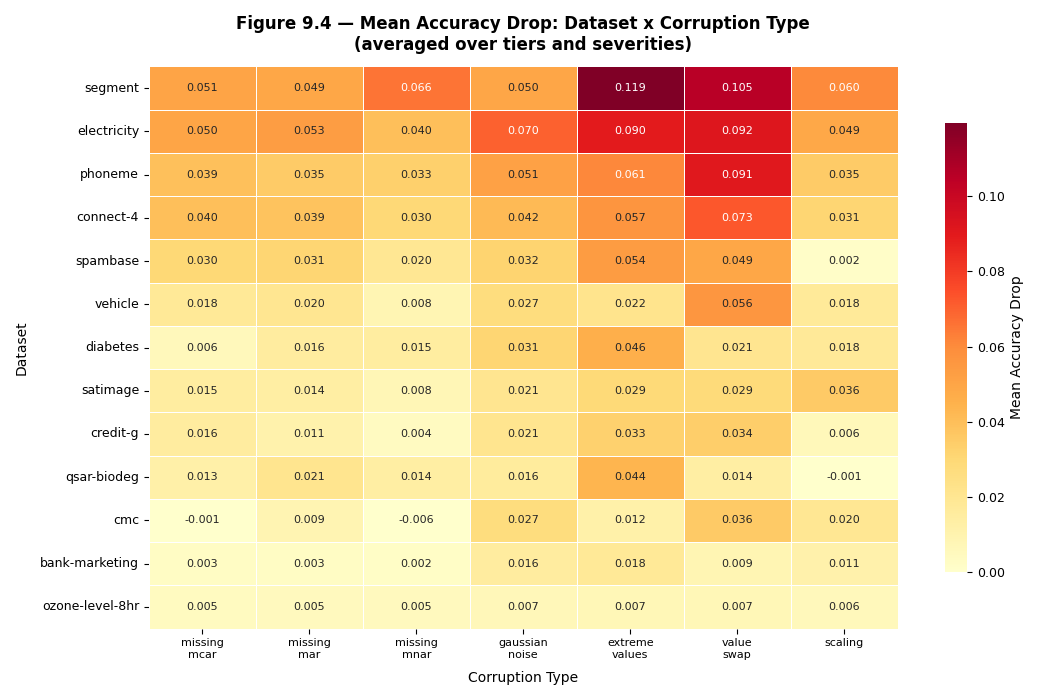

Saved: fig9_4_heatmap.png


In [18]:
# Fig 9.4 — Heatmap: accuracy drop by dataset x corruption type
fig, ax = plt.subplots(figsize=(11, 7))
corr_order = ['missing_mcar','missing_mar','missing_mnar',
              'gaussian_noise','extreme_values','value_swap','scaling']
hm = (res_df.groupby(['dataset','corruption_type'])['accuracy_drop']
      .mean().unstack())
hm = hm.reindex(columns=[c for c in corr_order if c in hm.columns])
hm = hm.loc[hm.mean(axis=1).sort_values(ascending=False).index]
sns.heatmap(hm, ax=ax, cmap='YlOrRd',
            annot=True, fmt='.3f', annot_kws={'size': 8},
            linewidths=0.5, linecolor='white', vmin=0,
            cbar_kws={'label': 'Mean Accuracy Drop', 'shrink': 0.8})
ax.set_xlabel('Corruption Type', labelpad=8)
ax.set_ylabel('Dataset', labelpad=8)
ax.set_title('Figure 9.4 — Mean Accuracy Drop: Dataset x Corruption Type\n'
             '(averaged over tiers and severities)', pad=12)
ax.set_xticklabels([c.replace('_','\n') for c in hm.columns], fontsize=8)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=9)
plt.tight_layout()
fig.savefig('report_figures/fig9_4_heatmap.png', dpi=300)
plt.show(); print("Saved: fig9_4_heatmap.png")

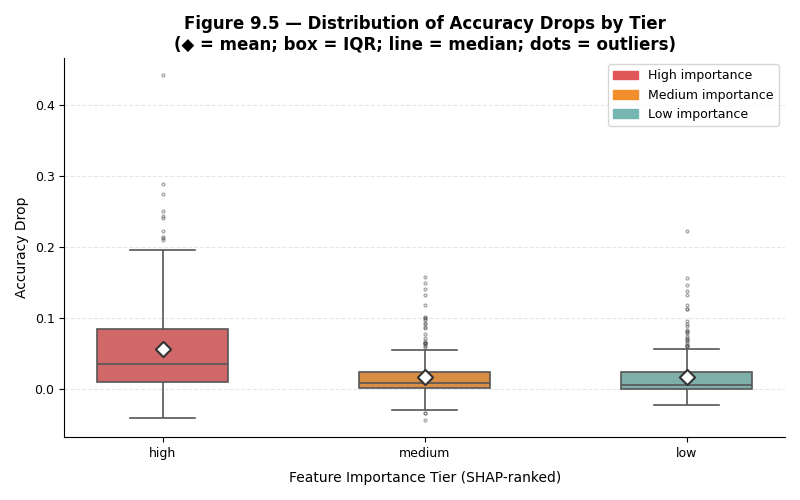

Saved: fig9_5_boxplot_by_tier.png


In [19]:
# Fig 9.5 — Box plot of accuracy drops by tier
fig, ax = plt.subplots(figsize=(8, 5))
tier_order = ['high', 'medium', 'low']
palette    = {t: TIER_COLORS[t] for t in tier_order}
sns.boxplot(data=res_df, x='tier', y='accuracy_drop',
            order=tier_order, palette=palette,
            width=0.5, linewidth=1.2,
            flierprops=dict(marker='.', markersize=4, alpha=0.5),
            ax=ax)
tier_means = res_df.groupby('tier')['accuracy_drop'].mean()
for i, t in enumerate(tier_order):
    ax.scatter(i, tier_means[t], marker='D', color='white',
               s=60, zorder=5, edgecolors='#333', linewidth=1.5)
patches = [mpatches.Patch(color=TIER_COLORS[t],
                           label=f'{t.capitalize()} importance')
           for t in tier_order]
ax.legend(handles=patches, fontsize=9)
ax.set_xlabel('Feature Importance Tier (SHAP-ranked)', labelpad=8)
ax.set_ylabel('Accuracy Drop')
ax.set_title('Figure 9.5 — Distribution of Accuracy Drops by Tier\n'
             '(◆ = mean; box = IQR; line = median; dots = outliers)')
plt.tight_layout()
fig.savefig('report_figures/fig9_5_boxplot_by_tier.png', dpi=300)
plt.show(); print("Saved: fig9_5_boxplot_by_tier.png")

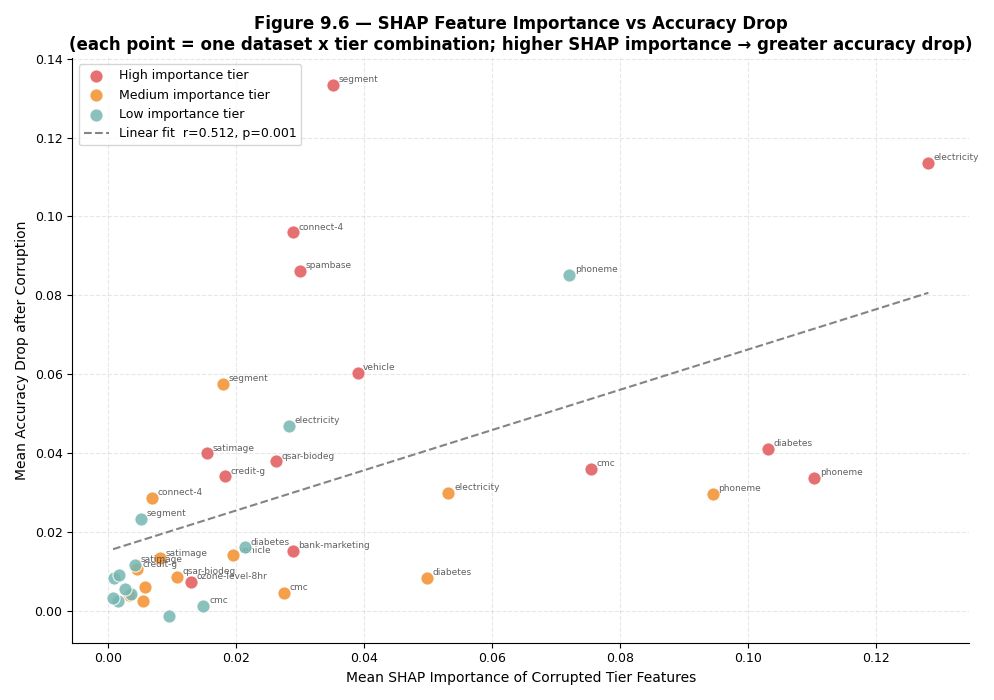

Saved: fig9_6_shap_vs_accuracy_drop.png
Pearson r = 0.5120, p = 0.0009


In [20]:
# Fig 9.6 — SCATTER: mean SHAP tier importance vs mean accuracy drop
#            39 points (13 datasets x 3 tiers), coloured by tier
# Step 1: compute mean SHAP importance per (dataset, tier)
# Use plan_df to get which features belong to each tier, then look up SHAP files
tier_feat = (plan_df[['dataset','tier','features']]
             .drop_duplicates(subset=['dataset','tier']))

shap_rows = []
for _, row in tier_feat.iterrows():
    name  = row['dataset']
    tier  = row['tier']
    feats = row['features'].split('|')
    sd    = pd.read_csv(f'shap/{name}_shap_importance.csv')
    matched = sd[sd['feature'].isin(feats)]['shap_importance']
    if len(matched) > 0:
        shap_rows.append({'dataset': name, 'tier': tier,
                          'mean_tier_shap': matched.mean()})
tier_shap_df = pd.DataFrame(shap_rows)

# Step 2: aggregate accuracy drop per (dataset, tier)
agg = (res_df.groupby(['dataset','tier'])['accuracy_drop']
       .mean().reset_index()
       .rename(columns={'accuracy_drop': 'mean_acc_drop'}))
scatter_df = agg.merge(tier_shap_df, on=['dataset','tier'])

# Step 3: plot
fig, ax = plt.subplots(figsize=(10, 7))
for tier in ['high', 'medium', 'low']:
    sub = scatter_df[scatter_df['tier']==tier]
    ax.scatter(sub['mean_tier_shap'], sub['mean_acc_drop'],
               c=TIER_COLORS[tier], s=90, alpha=0.85, zorder=3,
               edgecolors='white', linewidth=0.8,
               label=f'{tier.capitalize()} importance tier')
    # Label all points except those where both x and y are below 0.01
    for _, r in sub.iterrows():
        if not (r['mean_tier_shap'] < 0.01 and r['mean_acc_drop'] < 0.01):
            ax.annotate(r['dataset'], (r['mean_tier_shap'], r['mean_acc_drop']),
                        textcoords='offset points', xytext=(4, 2),
                        fontsize=6.5, color='#444', alpha=0.85)

# Regression line over all points
from scipy.stats import pearsonr
x_all = scatter_df['mean_tier_shap'].values
y_all = scatter_df['mean_acc_drop'].values
m, b  = np.polyfit(x_all, y_all, 1)
r, p  = pearsonr(x_all, y_all)
xs    = np.linspace(x_all.min(), x_all.max(), 100)
ax.plot(xs, m*xs + b, '--', color='#333', linewidth=1.5, alpha=0.6,
        label=f'Linear fit  r={r:.3f}, p={p:.3f}')

ax.set_xlabel('Mean SHAP Importance of Corrupted Tier Features')
ax.set_ylabel('Mean Accuracy Drop after Corruption')
ax.set_title('Figure 9.6 — SHAP Feature Importance vs Accuracy Drop\n'
             '(each point = one dataset x tier combination; '
             'higher SHAP importance → greater accuracy drop)')
ax.legend(fontsize=9, loc='upper left')
plt.tight_layout()
fig.savefig('report_figures/fig9_6_shap_vs_accuracy_drop.png', dpi=300)
plt.show()
print(f"Saved: fig9_6_shap_vs_accuracy_drop.png")
print(f"Pearson r = {r:.4f}, p = {p:.4f}")

## Step 10 — Drift Measurement

In [21]:
drift_df = pd.read_csv('step10_drift_results.csv')
print(f"Drift results: {len(drift_df)} experiments")
print(drift_df.groupby('tier')['mean_ks_stat'].mean().round(4).to_string())

Drift results: 807 experiments
tier
high      0.1838
low       0.1975
medium    0.1833


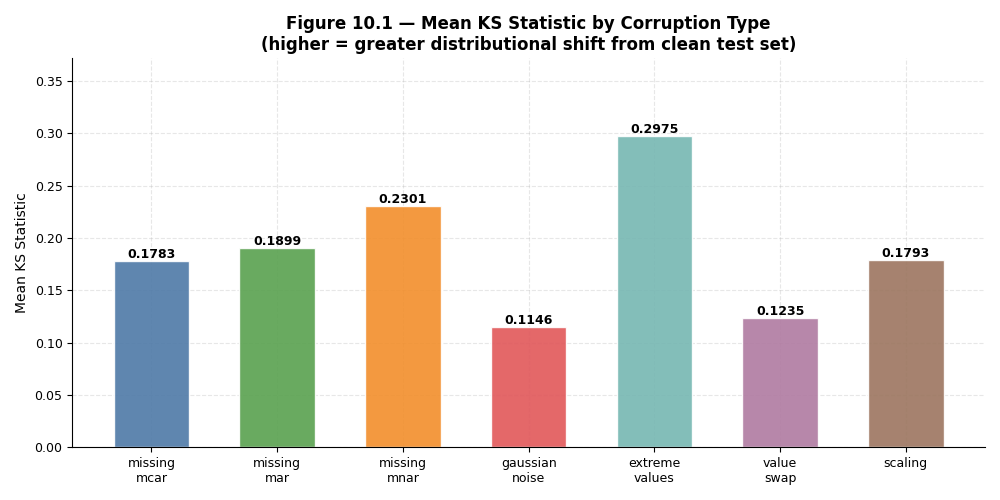

Saved: fig10_1_ks_by_corruption.png


In [22]:
# Fig 10.1 — Mean KS statistic by corruption type
corr_order = ['missing_mcar','missing_mar','missing_mnar',
              'gaussian_noise','extreme_values','value_swap','scaling']
ks_by_ct = (drift_df.groupby('corruption_type')['mean_ks_stat']
            .mean().reindex(corr_order).dropna())
cols = [CORR_COLORS.get(c,'#999') for c in ks_by_ct.index]

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(range(len(ks_by_ct)), ks_by_ct.values,
              color=cols, edgecolor='white', alpha=0.9, width=0.6)
ax.set_xticks(range(len(ks_by_ct)))
ax.set_xticklabels([c.replace('_','\n') for c in ks_by_ct.index], fontsize=9)
for bar, v in zip(bars, ks_by_ct.values):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.003,
            f'{v:.4f}', ha='center', fontsize=9, fontweight='bold')
ax.set_ylabel('Mean KS Statistic')
ax.set_title('Figure 10.1 — Mean KS Statistic by Corruption Type\n'
             '(higher = greater distributional shift from clean test set)')
ax.set_ylim(0, ks_by_ct.max()*1.25)
plt.tight_layout()
fig.savefig('report_figures/fig10_1_ks_by_corruption.png', dpi=300)
plt.show(); print("Saved: fig10_1_ks_by_corruption.png")

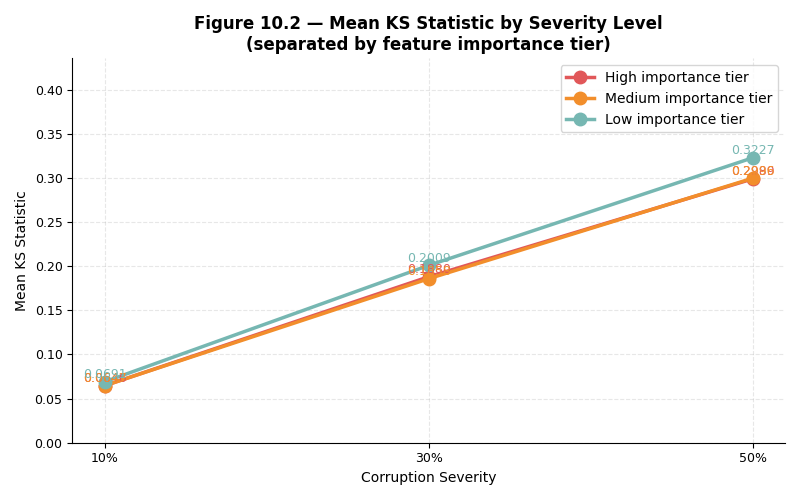

Saved: fig10_2_ks_by_severity.png


In [23]:
# Fig 10.2 — Mean KS statistic by severity, separated by tier (line chart)
tier_order = ['high', 'medium', 'low']
sev_vals   = sorted(drift_df['severity'].unique())
sev_labels = [f'{int(s*100)}%' for s in sev_vals]

fig, ax = plt.subplots(figsize=(8, 5))
for tier in tier_order:
    sub   = drift_df[drift_df['tier']==tier]
    means = sub.groupby('severity')['mean_ks_stat'].mean()[sev_vals].values
    ax.plot(sev_labels, means, marker='o', markersize=9, linewidth=2.5,
            color=TIER_COLORS[tier], label=f'{tier.capitalize()} importance tier')
    for x, y in zip(sev_labels, means):
        ax.text(x, y+0.004, f'{y:.4f}', ha='center', fontsize=9,
                color=TIER_COLORS[tier])
ymax = drift_df.groupby(['tier','severity'])['mean_ks_stat'].mean().max()
ax.set_xlabel('Corruption Severity')
ax.set_ylabel('Mean KS Statistic')
ax.set_title('Figure 10.2 — Mean KS Statistic by Severity Level\n'
             '(separated by feature importance tier)')
ax.legend(fontsize=10)
ax.set_ylim(0, ymax*1.35)
plt.tight_layout()
fig.savefig('report_figures/fig10_2_ks_by_severity.png', dpi=300)
plt.show(); print("Saved: fig10_2_ks_by_severity.png")

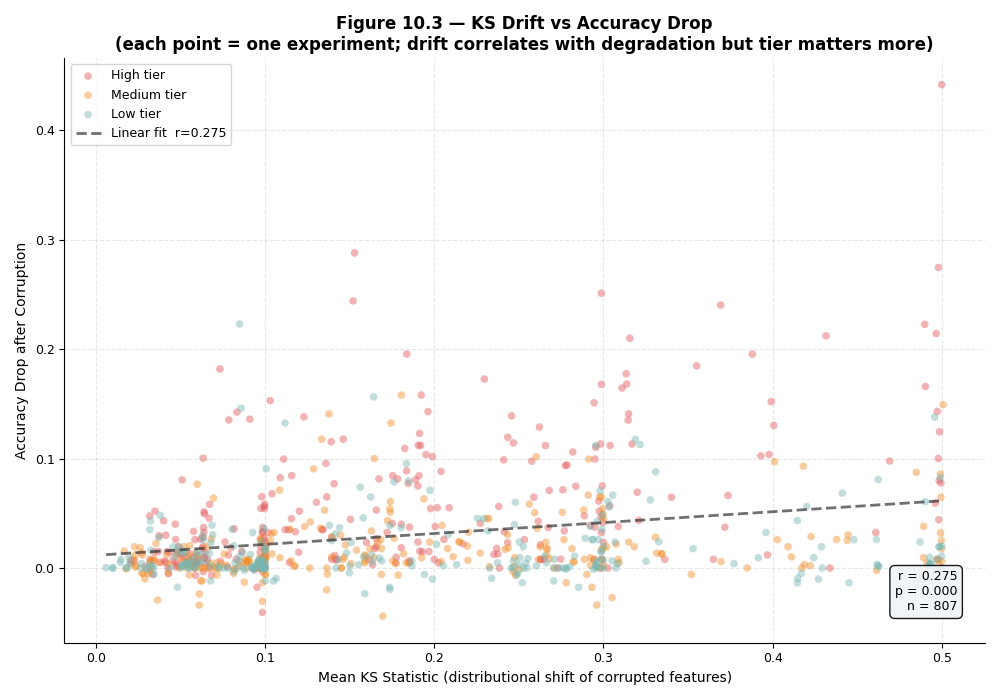

Saved: fig10_3_ks_vs_accuracy_drop.png  (r=0.2755, p=0.0000)


In [24]:
# Fig 10.3 — Scatter: KS statistic vs accuracy drop (per experiment, coloured by tier)
from scipy.stats import pearsonr as _pearsonr
res_drift = drift_df.merge(
    res_df[['dataset','tier','corruption_type','severity','accuracy_drop']],
    on=['dataset','tier','corruption_type','severity'])

fig, ax = plt.subplots(figsize=(10, 7))
for tier in ['high', 'medium', 'low']:
    sub = res_drift[res_drift['tier']==tier]
    ax.scatter(sub['mean_ks_stat'], sub['accuracy_drop'],
               c=TIER_COLORS[tier], s=30, alpha=0.45,
               edgecolors='none', label=f'{tier.capitalize()} tier')

x_all = res_drift['mean_ks_stat'].values
y_all = res_drift['accuracy_drop'].values
m, b  = np.polyfit(x_all, y_all, 1)
r, p  = _pearsonr(x_all, y_all)
xs    = np.linspace(x_all.min(), x_all.max(), 100)
ax.plot(xs, m*xs + b, '--', color='#333', linewidth=2, alpha=0.7,
        label=f'Linear fit  r={r:.3f}')
ax.set_xlabel('Mean KS Statistic (distributional shift of corrupted features)')
ax.set_ylabel('Accuracy Drop after Corruption')
ax.set_title('Figure 10.3 — KS Drift vs Accuracy Drop\n'
             '(each point = one experiment; drift correlates with degradation but tier matters more)')
ax.legend(fontsize=9, loc='upper left')
ax.text(0.97, 0.05, f'r = {r:.3f}\np = {p:.3f}\nn = {len(res_drift)}',
        transform=ax.transAxes, ha='right', va='bottom', fontsize=9,
        bbox=dict(boxstyle='round,pad=0.4', facecolor='#F0F4F8', alpha=0.9))
plt.tight_layout()
fig.savefig('report_figures/fig10_3_ks_vs_accuracy_drop.png', dpi=300)
plt.show()
print(f"Saved: fig10_3_ks_vs_accuracy_drop.png  (r={r:.4f}, p={p:.4f})")

## Step 11 — Meta-Model Building

In [25]:
feat_imp_df = pd.read_csv('step11_rf_feature_importance.csv')
lr_coef_df  = pd.read_csv('step11_lr_coefficients.csv')
preds11_df  = pd.read_csv('step11_predictions.csv')
meta_df     = pd.read_csv('step11_meta_features.csv')
print(f"Feature importances: {len(feat_imp_df)} features")
print(f"Predictions: {len(preds11_df)} experiments")

Feature importances: 19 features
Predictions: 807 experiments


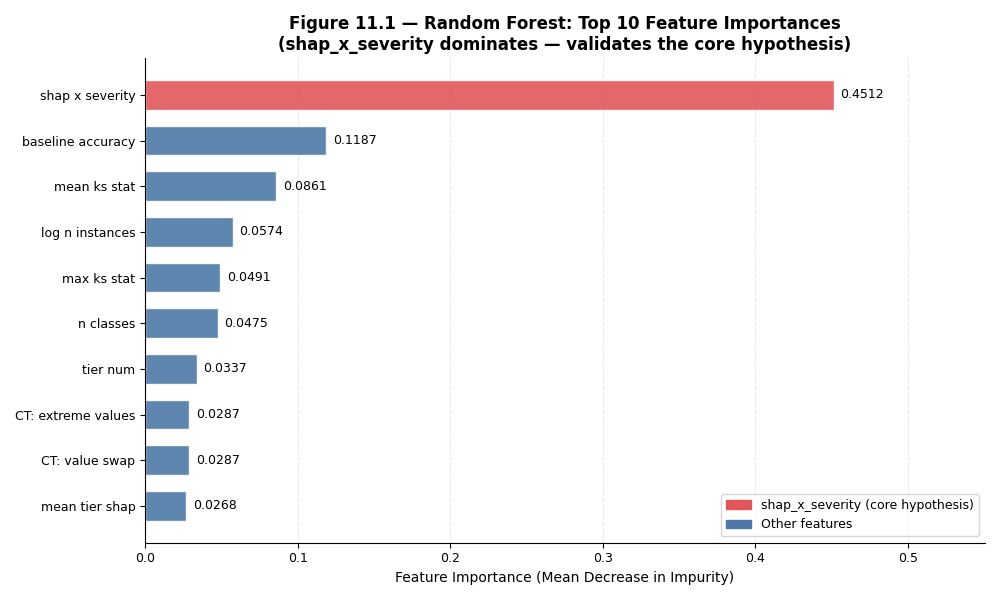

Saved: fig11_1_rf_feature_importance.png


In [26]:
# Fig 11.1 — Horizontal bar: top 10 RF feature importances
top10 = feat_imp_df.head(10).copy()
top10['label'] = (top10['feature']
                  .str.replace('ct_', 'CT: ', regex=False)
                  .str.replace('_', ' '))
colors_fi = ['#E15759' if f == 'shap_x_severity' else '#4E79A7'
             for f in top10['feature']]

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(top10['label'][::-1], top10['importance'][::-1],
               color=colors_fi[::-1], height=0.65,
               edgecolor='white', alpha=0.9)
xmax = top10['importance'].max()
for bar, v in zip(bars, top10['importance'][::-1]):
    ax.text(bar.get_width() + xmax*0.01,
            bar.get_y()+bar.get_height()/2,
            f'{v:.4f}', va='center', fontsize=9)
p1 = mpatches.Patch(color='#E15759', label='shap_x_severity (core hypothesis)')
p2 = mpatches.Patch(color='#4E79A7', label='Other features')
ax.legend(handles=[p1,p2], fontsize=9, loc='lower right')
ax.set_xlabel('Feature Importance (Mean Decrease in Impurity)')
ax.set_title('Figure 11.1 — Random Forest: Top 10 Feature Importances\n'
             '(shap_x_severity dominates — validates the core hypothesis)')
ax.set_xlim(0, xmax*1.22)
ax.grid(axis='x', alpha=0.3); ax.grid(axis='y', alpha=0)
plt.tight_layout()
fig.savefig('report_figures/fig11_1_rf_feature_importance.png', dpi=300)
plt.show(); print("Saved: fig11_1_rf_feature_importance.png")

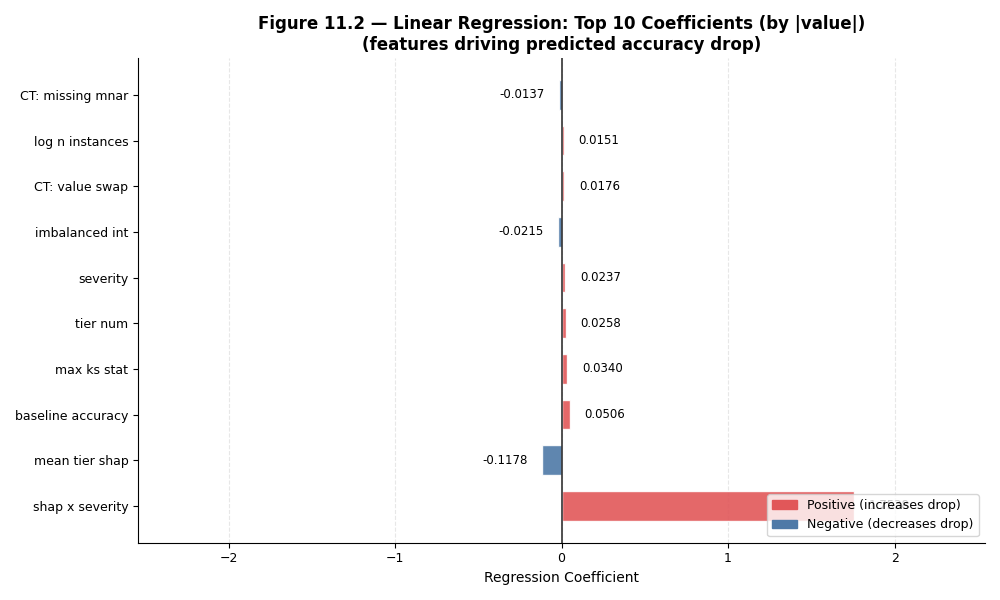

Saved: fig11_2_lr_coefficients.png


In [27]:
# Fig 11.2 — Linear regression coefficients (top 10 by |coef|)
top10c = lr_coef_df.head(10).copy()
top10c['label'] = (top10c['feature']
                   .str.replace('ct_', 'CT: ', regex=False)
                   .str.replace('_', ' '))

fig, ax = plt.subplots(figsize=(10, 6))
colors_lr = ['#E15759' if v >= 0 else '#4E79A7'
             for v in top10c['coefficient']]
ax.barh(top10c['label'], top10c['coefficient'],
        color=colors_lr, height=0.65, edgecolor='white', alpha=0.9)
ax.axvline(0, color='#333', linewidth=1.2)
xabs = top10c['coefficient'].abs().max()
ax.set_xlim(-xabs*1.45, xabs*1.45)
for _, row in top10c.iterrows():
    offset = row['coefficient'] + np.sign(row['coefficient']) * xabs*0.05
    ax.text(offset, top10c.index.get_loc(row.name),
            f'{row["coefficient"]:.4f}', va='center', fontsize=8.5,
            ha='left' if row['coefficient'] >= 0 else 'right')
p1 = mpatches.Patch(color='#E15759', label='Positive (increases drop)')
p2 = mpatches.Patch(color='#4E79A7', label='Negative (decreases drop)')
ax.legend(handles=[p1,p2], fontsize=9, loc='lower right')
ax.set_xlabel('Regression Coefficient')
ax.set_title('Figure 11.2 — Linear Regression: Top 10 Coefficients (by |value|)\n'
             '(features driving predicted accuracy drop)')
ax.grid(axis='x', alpha=0.3); ax.grid(axis='y', alpha=0)
plt.tight_layout()
fig.savefig('report_figures/fig11_2_lr_coefficients.png', dpi=300)
plt.show(); print("Saved: fig11_2_lr_coefficients.png")

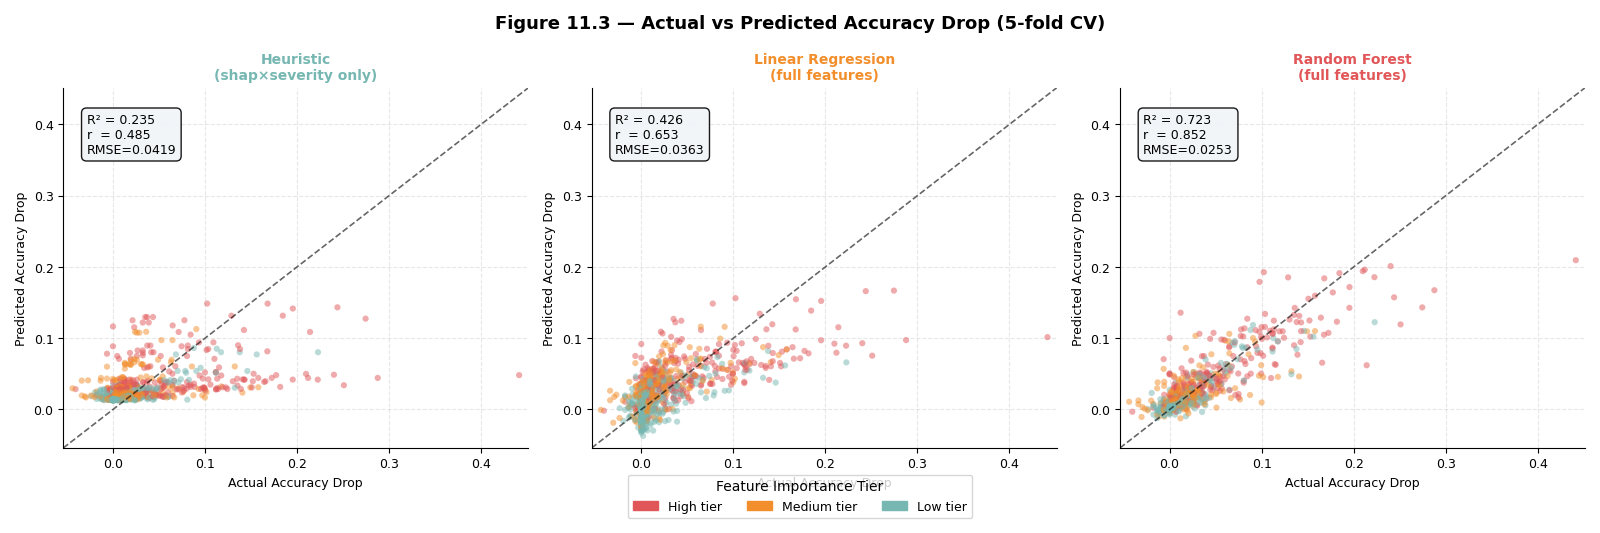

Saved: fig11_3_actual_vs_predicted.png


In [28]:
# Fig 11.3 — Actual vs Predicted: 3 models side by side (5-fold CV)
from scipy.stats import pearsonr as _pearsonr

model_cols   = ['pred_heuristic', 'pred_lr', 'pred_rf']
model_names  = ['Heuristic\n(shap×severity only)',
                'Linear Regression\n(full features)',
                'Random Forest\n(full features)']
model_colors = ['#76B7B2', '#F28E2B', '#E15759']
tier_col     = meta_df['tier'].map(TIER_COLORS)
y_true       = preds11_df['accuracy_drop'].values

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Figure 11.3 — Actual vs Predicted Accuracy Drop (5-fold CV)',
             fontsize=13, fontweight='bold')

for ax, col, name, color in zip(axes, model_cols, model_names, model_colors):
    y_pred = preds11_df[col].values
    r, _   = _pearsonr(y_true, y_pred)
    rmse   = float(np.sqrt(np.mean((y_true - y_pred)**2)))
    r2     = float(1 - np.sum((y_true-y_pred)**2) /
                       np.sum((y_true-y_true.mean())**2))
    lims   = [min(y_true.min(), y_pred.min())-0.01,
              max(y_true.max(), y_pred.max())+0.01]
    ax.scatter(y_true, y_pred, c=tier_col, s=20, alpha=0.5, edgecolors='none')
    ax.plot(lims, lims, 'k--', linewidth=1.2, alpha=0.6)
    ax.set_xlim(lims); ax.set_ylim(lims)
    ax.set_xlabel('Actual Accuracy Drop', fontsize=9)
    ax.set_ylabel('Predicted Accuracy Drop', fontsize=9)
    ax.set_title(name, fontsize=10, fontweight='bold', color=color)
    ax.text(0.05, 0.93, f'R² = {r2:.3f}\nr  = {r:.3f}\nRMSE={rmse:.4f}',
            transform=ax.transAxes, fontsize=9, va='top',
            bbox=dict(boxstyle='round,pad=0.4', facecolor='#F0F4F8', alpha=0.9))
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)

patches = [mpatches.Patch(color=TIER_COLORS[t], label=f'{t.capitalize()} tier')
           for t in ['high','medium','low']]
fig.legend(handles=patches, fontsize=9, loc='lower center',
           ncol=3, bbox_to_anchor=(0.5, -0.04), title='Feature Importance Tier')
plt.tight_layout()
fig.savefig('report_figures/fig11_3_actual_vs_predicted.png', dpi=300, bbox_inches='tight')
plt.show(); print("Saved: fig11_3_actual_vs_predicted.png")

## Step 12 — Severity-Only Baseline

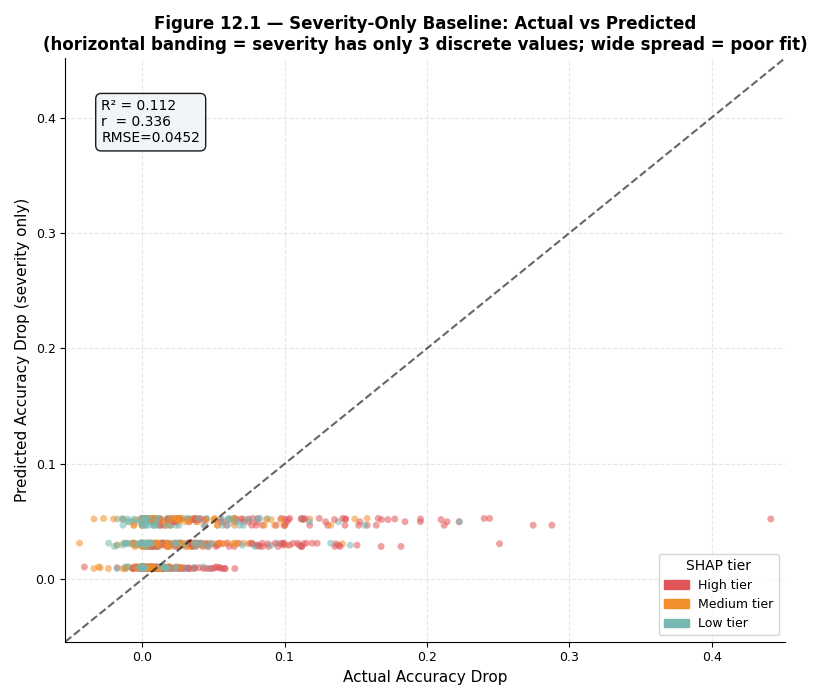

Saved: fig12_1_severity_baseline.png  R²=0.1124  r=0.3356


In [29]:
# Fig 12.1 — Severity-only predicted vs actual
#            Horizontal banding reveals 3 discrete severity values — severity alone is not enough
from scipy.stats import pearsonr as _pearsonr
preds12_df = pd.read_csv('step12_predictions.csv')
y_true     = preds12_df['accuracy_drop'].values
y_pred_s   = preds12_df['pred_severity_only'].values
r, _       = _pearsonr(y_true, y_pred_s)
rmse       = float(np.sqrt(np.mean((y_true - y_pred_s)**2)))
r2         = float(1 - np.sum((y_true-y_pred_s)**2) /
                       np.sum((y_true-y_true.mean())**2))

fig, ax = plt.subplots(figsize=(8, 7))
tier_col = meta_df['tier'].map(TIER_COLORS)
ax.scatter(y_true, y_pred_s, c=tier_col, s=25, alpha=0.55, edgecolors='none')
lims = [min(y_true.min(), y_pred_s.min())-0.01,
        max(y_true.max(), y_pred_s.max())+0.01]
ax.plot(lims, lims, 'k--', linewidth=1.5, alpha=0.6, label='Perfect prediction')
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel('Actual Accuracy Drop', fontsize=11)
ax.set_ylabel('Predicted Accuracy Drop (severity only)', fontsize=11)
ax.set_title('Figure 12.1 — Severity-Only Baseline: Actual vs Predicted\n'
             '(horizontal banding = severity has only 3 discrete values; '
             'wide spread = poor fit)', fontsize=12)
ax.text(0.05, 0.93, f'R² = {r2:.3f}\nr  = {r:.3f}\nRMSE={rmse:.4f}',
        transform=ax.transAxes, fontsize=10, va='top',
        bbox=dict(boxstyle='round,pad=0.4', facecolor='#F0F4F8', alpha=0.9))
patches = [mpatches.Patch(color=TIER_COLORS[t], label=f'{t.capitalize()} tier')
           for t in ['high','medium','low']]
ax.legend(handles=patches, fontsize=9, title='SHAP tier', loc='lower right')
plt.tight_layout()
fig.savefig('report_figures/fig12_1_severity_baseline.png', dpi=300)
plt.show()
print(f"Saved: fig12_1_severity_baseline.png  R²={r2:.4f}  r={r:.4f}")

## Step 13 — Final Evaluation & Comparison

In [30]:
eval_df    = pd.read_csv('step13_all_metrics.csv')
fold_df    = pd.read_csv('step13_fold_metrics.csv')
rf_tier_df = pd.read_csv('step13_rf_by_tier.csv')
rf_corr_df = pd.read_csv('step13_rf_by_corruption.csv')
rf_sev_df  = pd.read_csv('step13_rf_by_severity.csv')
print("Models in comparison (mean ± std across 5 folds):")
for _, row in fold_df.iterrows():
    print(f"  {row['model']:45s}  RMSE={row['rmse_mean']:.5f}±{row['rmse_std']:.5f}"
          f"  R²={row['r2_mean']:.4f}±{row['r2_std']:.4f}"
          f"  r={row['pearson_r_mean']:.4f}±{row['pearson_r_std']:.4f}")

Models in comparison (mean ± std across 5 folds):
  Severity-Only Baseline                         RMSE=0.04476±0.00608  R²=0.1091±0.0338  r=0.3548±0.0620
  Severity + Severity² Baseline                  RMSE=0.04477±0.00608  R²=0.1088±0.0345  r=0.3539±0.0623
  Heuristic (shap_x_severity only)               RMSE=0.04154±0.00568  R²=0.2259±0.0975  r=0.5036±0.1007
  Linear Regression (full features)              RMSE=0.03614±0.00382  R²=0.4107±0.0706  r=0.6643±0.0457
  Random Forest Regressor                        RMSE=0.02507±0.00300  R²=0.7168±0.0368  r=0.8548±0.0262


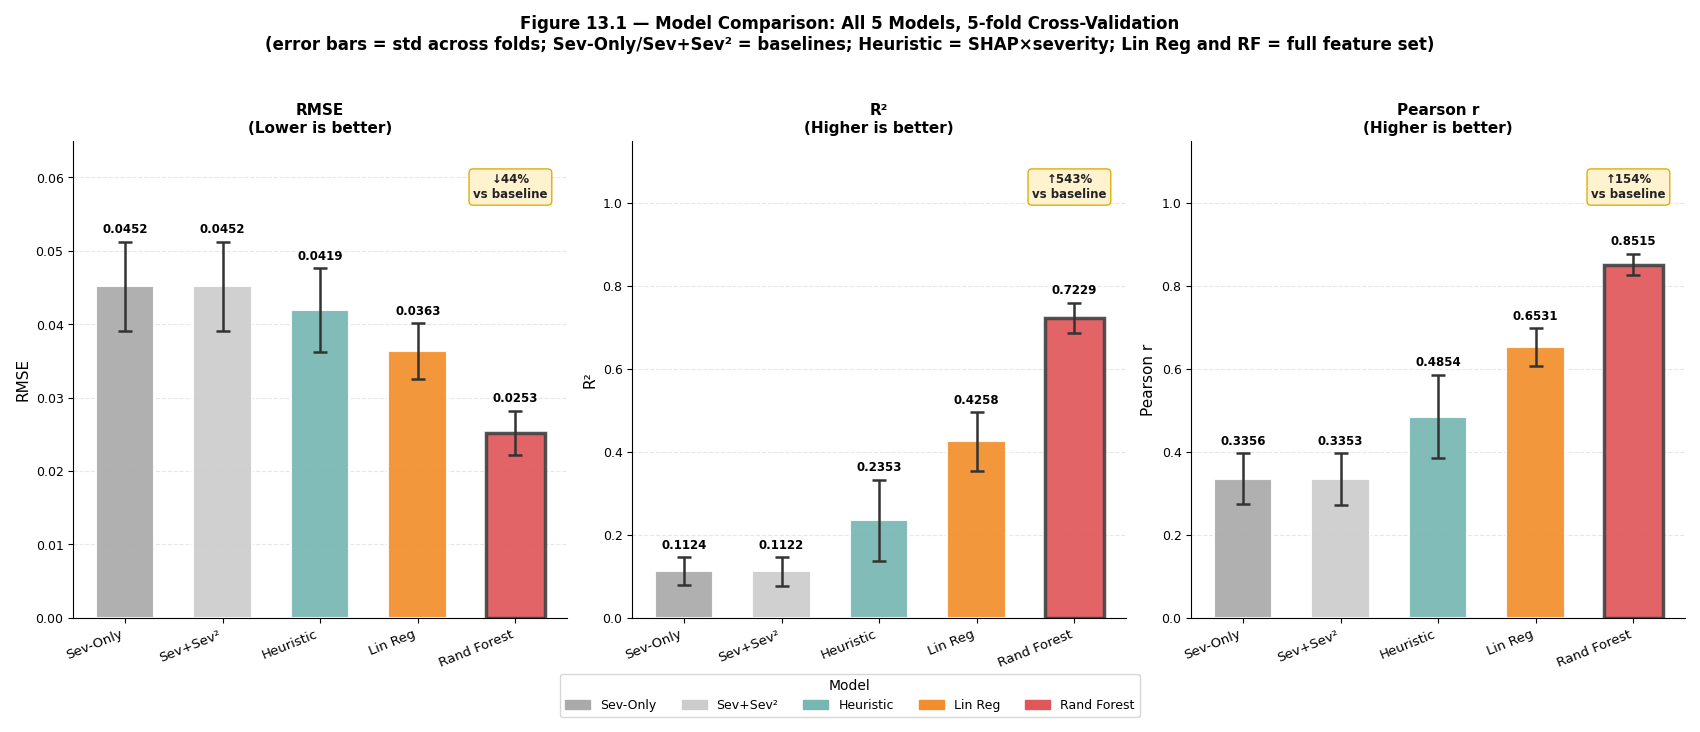

Saved: fig13_1_model_comparison.png


In [68]:
# Fig 13.1 — KEY FIGURE: grouped bar chart comparing all 5 models (RMSE, R², r)
MODEL_SHORT = {
    'Severity-Only Baseline':              'Sev-Only',
    'Severity + Severity² Baseline':       'Sev+Sev²',
    'Heuristic (shap_x_severity only)':    'Heuristic',
    'Linear Regression (full features)':   'Lin Reg',
    'Random Forest Regressor':             'Rand Forest',
}
MODEL_COLORS = ['#AAAAAA', '#CCCCCC', '#76B7B2', '#F28E2B', '#E15759']
eval_df['short'] = eval_df['model'].map(MODEL_SHORT)
fold_df['short'] = fold_df['model'].map(MODEL_SHORT)
order = ['Sev-Only', 'Sev+Sev²', 'Heuristic', 'Lin Reg', 'Rand Forest']

# means from original cross_val_predict (unchanged numbers), stds from per-fold CV
metrics_cfg = [
    ('rmse',      'rmse_std',      'RMSE',      'Lower is better',    True,  0.065),
    ('r2',        'r2_std',        'R²',        'Higher is better',   False, 1.15),
    ('pearson_r', 'pearson_r_std', 'Pearson r', 'Higher is better',   False, 1.15),
]

fig, axes = plt.subplots(1, 3, figsize=(17, 6.5))
fig.suptitle('Figure 13.1 — Model Comparison: All 5 Models, 5-fold Cross-Validation\n'
             '(error bars = std across folds; Sev-Only/Sev+Sev² = baselines; '
             'Heuristic = SHAP×severity; Lin Reg and RF = full feature set)',
             fontsize=12, fontweight='bold', y=1.03)

for ax, (mean_col, std_col, title, subtitle, lower_better, ylim_top) in zip(axes, metrics_cfg):
    vals = [float(eval_df.loc[eval_df['short']==m, mean_col].iloc[0]) for m in order]
    stds = [float(fold_df.loc[fold_df['short']==m, std_col].iloc[0])  for m in order]

    bars = ax.bar(order, vals, color=MODEL_COLORS,
                  edgecolor='white', linewidth=1.5, alpha=0.92, width=0.6,
                  yerr=stds,
                  error_kw=dict(ecolor='#333333', elinewidth=1.8,
                                capsize=5, capthick=1.8, zorder=5))

    # Value annotations above error bar cap
    for bar, v, s in zip(bars, vals, stds):
        ax.text(bar.get_x()+bar.get_width()/2,
                v + s + ylim_top*0.018,
                f'{v:.4f}', ha='center', fontsize=8.5, fontweight='bold')

    # Emphasise RF with a darker border
    bars[-1].set_edgecolor('#444444')
    bars[-1].set_linewidth(2.5)

    # % improvement over Sev-Only baseline
    base_val = vals[0]
    rf_val   = vals[-1]
    improve  = abs(rf_val - base_val) / abs(base_val) * 100
    direction = '↓' if lower_better else '↑'
    ax.annotate(f'{direction}{improve:.0f}%\nvs baseline',
                xy=(len(order)-1, rf_val),
                xytext=(len(order)-1.05, ylim_top*0.88),
                ha='center', fontsize=8.5, fontweight='bold', color='#222',
                bbox=dict(boxstyle='round,pad=0.35', facecolor='#FFF3CD',
                          edgecolor='#DDAA00', alpha=0.95))

    ax.set_xticks(range(len(order)))
    ax.set_xticklabels(order, rotation=22, ha='right', fontsize=9.5)
    ax.set_ylabel(f'{title}', fontsize=11)
    ax.set_ylim(0, ylim_top)
    ax.set_title(f'{title}\n({subtitle})', fontsize=11, fontweight='bold')
    ax.grid(axis='y', alpha=0.3); ax.grid(axis='x', alpha=0)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# Shared model colour legend
patches_m = [mpatches.Patch(color=c, label=m)
             for c, m in zip(MODEL_COLORS, order)]
fig.legend(handles=patches_m, fontsize=9, loc='lower center',
           ncol=5, bbox_to_anchor=(0.5, -0.06), title='Model')
plt.tight_layout()
fig.savefig('report_figures/fig13_1_model_comparison.png', dpi=300, bbox_inches='tight')
plt.show(); print("Saved: fig13_1_model_comparison.png")

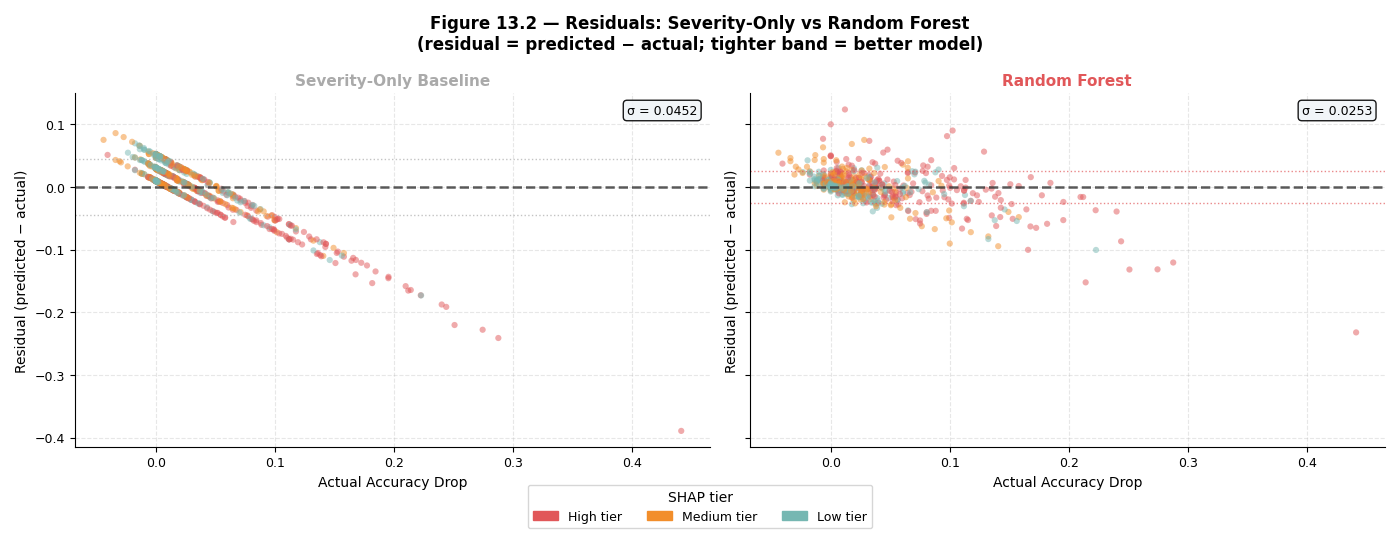

Saved: fig13_2_residuals.png


In [32]:
# Fig 13.2 — Residual plot: Severity-Only vs RF
#            Shows dramatically tighter spread for RF
y_true    = preds12_df['accuracy_drop'].values
resid_sev = preds12_df['pred_severity_only'].values - y_true
resid_rf  = preds11_df['pred_rf'].values - y_true
tier_col  = meta_df['tier'].map(TIER_COLORS)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
fig.suptitle('Figure 13.2 — Residuals: Severity-Only vs Random Forest\n'
             '(residual = predicted − actual; tighter band = better model)',
             fontsize=12, fontweight='bold')

for ax, resid, name, color in zip(
        axes,
        [resid_sev, resid_rf],
        ['Severity-Only Baseline', 'Random Forest'],
        ['#AAAAAA', '#E15759']):
    ax.scatter(y_true, resid, c=tier_col, s=20, alpha=0.5, edgecolors='none')
    ax.axhline(0, color='#333', linewidth=1.8, linestyle='--', alpha=0.8,
               label='Zero residual')
    std = float(np.std(resid))
    ax.axhline(+std, color=color, linewidth=1, linestyle=':', alpha=0.7)
    ax.axhline(-std, color=color, linewidth=1, linestyle=':', alpha=0.7)
    ax.text(0.98, 0.97, f'σ = {std:.4f}',
            transform=ax.transAxes, ha='right', va='top', fontsize=9,
            bbox=dict(boxstyle='round,pad=0.3', facecolor='#F0F4F8', alpha=0.9))
    ax.set_xlabel('Actual Accuracy Drop', fontsize=10)
    ax.set_ylabel('Residual (predicted − actual)', fontsize=10)
    ax.set_title(name, fontsize=11, fontweight='bold', color=color)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

patches = [mpatches.Patch(color=TIER_COLORS[t], label=f'{t.capitalize()} tier')
           for t in ['high','medium','low']]
fig.legend(handles=patches, fontsize=9, loc='lower center',
           ncol=3, bbox_to_anchor=(0.5, -0.06), title='SHAP tier')
plt.tight_layout()
fig.savefig('report_figures/fig13_2_residuals.png', dpi=300, bbox_inches='tight')
plt.show(); print("Saved: fig13_2_residuals.png")

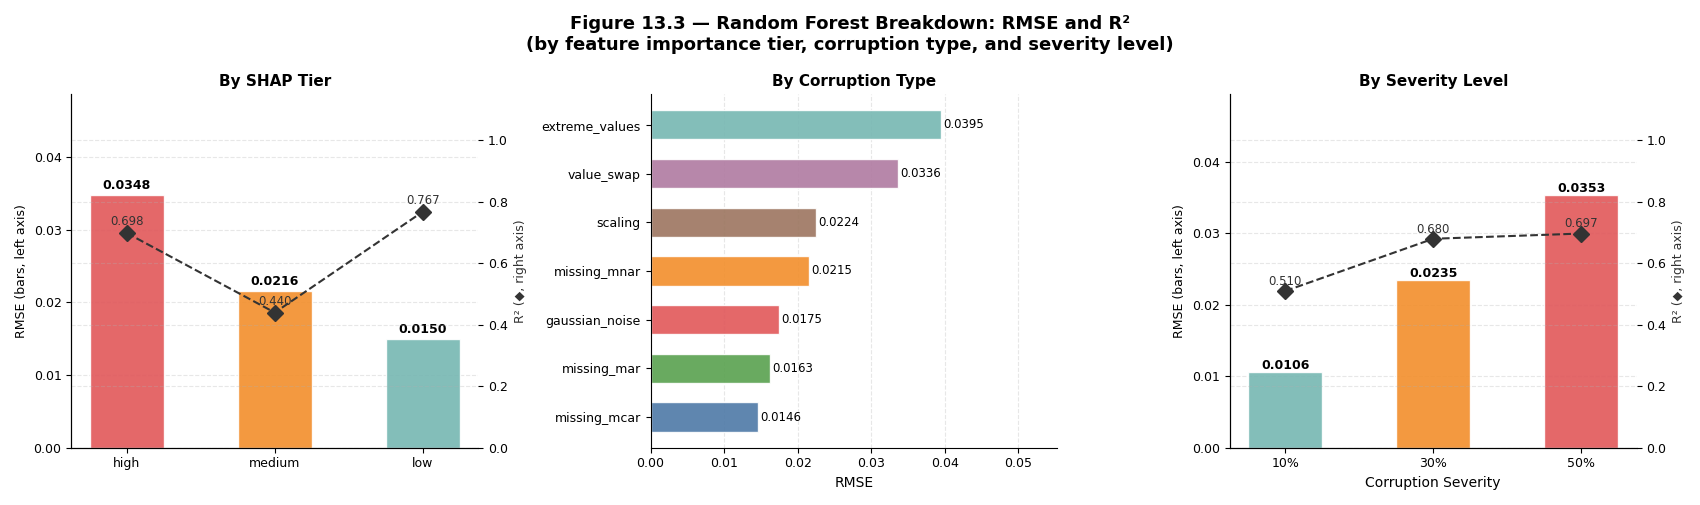

Saved: fig13_3_rf_breakdown.png


In [33]:
# Fig 13.3 — RF breakdown: by tier, corruption type, severity (3-panel)
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
fig.suptitle('Figure 13.3 — Random Forest Breakdown: RMSE and R²\n'
             '(by feature importance tier, corruption type, and severity level)',
             fontsize=13, fontweight='bold')

# Panel A: by tier
ax = axes[0]
tier_order = ['high', 'medium', 'low']
rft = rf_tier_df.set_index('tier').reindex(tier_order)
bars = ax.bar(tier_order, rft['rmse'].values,
              color=[TIER_COLORS[t] for t in tier_order],
              width=0.5, edgecolor='white', alpha=0.9)
for bar, v in zip(bars, rft['rmse'].values):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.0008,
            f'{v:.4f}', ha='center', fontsize=9, fontweight='bold')
ax2a = ax.twinx()
ax2a.plot(tier_order, rft['r2'].values, 'D--',
          color='#333', markersize=8, linewidth=1.5)
for x, y in zip(tier_order, rft['r2'].values):
    ax2a.text(x, y+0.025, f'{y:.3f}', ha='center', fontsize=8.5, color='#333')
ax2a.set_ylim(0, 1.15)
ax2a.set_ylabel('R² (◆, right axis)', fontsize=9, color='#333')
ax2a.spines['top'].set_visible(False)
ax.set_ylabel('RMSE (bars, left axis)', fontsize=9)
ax.set_ylim(0, rft['rmse'].max()*1.4)
ax.set_title('By SHAP Tier', fontsize=11, fontweight='bold')
ax.spines['top'].set_visible(False)
ax.grid(axis='y', alpha=0.3); ax.grid(axis='x', alpha=0)

# Panel B: by corruption type
ax = axes[1]
rfc = rf_corr_df.sort_values('rmse')
cols_ct = [CORR_COLORS.get(c,'#999') for c in rfc['corruption_type']]
bars = ax.barh(rfc['corruption_type'], rfc['rmse'].values,
               color=cols_ct, height=0.6, edgecolor='white', alpha=0.9)
for bar, v in zip(bars, rfc['rmse'].values):
    ax.text(bar.get_width()+0.0003, bar.get_y()+bar.get_height()/2,
            f'{v:.4f}', va='center', fontsize=8.5)
ax.set_xlabel('RMSE')
ax.set_title('By Corruption Type', fontsize=11, fontweight='bold')
ax.grid(axis='x', alpha=0.3); ax.grid(axis='y', alpha=0)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_xlim(0, rfc['rmse'].max()*1.4)

# Panel C: by severity
ax = axes[2]
rfs = rf_sev_df.sort_values('severity')
sev_labels = [f'{int(s*100)}%' for s in rfs['severity']]
bars = ax.bar(sev_labels, rfs['rmse'].values,
              color=['#76B7B2', '#F28E2B', '#E15759'],
              width=0.5, edgecolor='white', alpha=0.9)
for bar, v in zip(bars, rfs['rmse'].values):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.0004,
            f'{v:.4f}', ha='center', fontsize=9, fontweight='bold')
ax2c = ax.twinx()
ax2c.plot(sev_labels, rfs['r2'].values, 'D--',
          color='#333', markersize=8, linewidth=1.5)
for x, y in zip(sev_labels, rfs['r2'].values):
    ax2c.text(x, y+0.02, f'{y:.3f}', ha='center', fontsize=8.5, color='#333')
ax2c.set_ylim(0, 1.15)
ax2c.set_ylabel('R² (◆, right axis)', fontsize=9, color='#333')
ax2c.spines['top'].set_visible(False)
ax.set_ylabel('RMSE (bars, left axis)', fontsize=9)
ax.set_xlabel('Corruption Severity')
ax.set_ylim(0, rfs['rmse'].max()*1.4)
ax.set_title('By Severity Level', fontsize=11, fontweight='bold')
ax.spines['top'].set_visible(False)
ax.grid(axis='y', alpha=0.3); ax.grid(axis='x', alpha=0)

plt.tight_layout()
fig.savefig('report_figures/fig13_3_rf_breakdown.png', dpi=300, bbox_inches='tight')
plt.show(); print("Saved: fig13_3_rf_breakdown.png")

## Summary

All figures saved to `report_figures/`. See `step9_performance_results.csv` for the raw results.

In [34]:
import glob as _glob
pngs = sorted(_glob.glob('report_figures/*.png'))
print(f"\n{len(pngs)} figures saved to report_figures/:")
for p in pngs:
    size_kb = os.path.getsize(p) // 1024
    print(f"  {os.path.basename(p):60s}  {size_kb:4d} KB")


41 figures saved to report_figures/:
  fig10_1_ks_by_corruption.png                                   143 KB
  fig10_2_ks_by_severity.png                                     198 KB
  fig10_3_ks_vs_accuracy_drop.png                                430 KB
  fig11_1_rf_feature_importance.png                              188 KB
  fig11_2_lr_coefficients.png                                    175 KB
  fig11_3_actual_vs_predicted.png                                548 KB
  fig12_1_severity_baseline.png                                  290 KB
  fig13_1_model_comparison.png                                   294 KB
  fig13_2_residuals.png                                          370 KB
  fig13_3_rf_breakdown.png                                       297 KB
  fig1_1_dataset_sizes.png                                       150 KB
  fig1_2_features_per_dataset.png                                128 KB
  fig1_3_dataset_table.png                                       196 KB
  fig2_1_class_distributio